# VALORA AI: Apartment Asking Price Estimation and Prediction Uncertainty in Montenegro
## Notebook 02: Modelling

**Main question:** *How accurately can we estimate apartment asking prices in Montenegro, and how reliably can we quantify the uncertainty of these predictions?*
**Input:** `data/processed/valora_apartments_clean.csv`, produced by `01_eda.ipynb`.
**This notebook:**
- fixes the evaluation protocol before training;
- compares three baselines with my five original model types and three justified additions, and measures what the location cleaning is worth;
- chooses one point-estimation method by cross-validation and tests it **once**;
- adds **prediction intervals** (quantile regression) with one pre-registered test check;
- analyses where estimates and intervals fail.

## 1. TL;DR

- **Data:** 1,376 real apartment sale listings from `01_eda.ipynb`, split into 1,098 development and 278 test listings. The split is group-aware, so the same flat is never on both sides.
- **Point estimate:** the protocol was fixed before training, and under its selection rule the **practical valuer rule "city median €/m² × area" was chosen**.
  - It had the lowest cross-validation error (MAE **€50,527 ± 6,297**).
  - On the test set, used once, it is off by **€57,478 on average** (median error €28,532; R² 0.469). That is **44% lower MAE than the mean-price baseline**.
  - The best machine-learning candidate (log-target Ridge, CV MAE €51,595) is within one standard error. No ML model, including hybrid "rule + correction" models tested later, beat the rule reliably.
- **Correction of an earlier statement:** on the test set the tree models had a lower RMSE and higher R² than the rule. **This was not confirmed in cross-validation on the 1,098 development listings** (Random Forest out-of-fold R² 0.563 vs 0.582 for the rule), so it is a property of that one test sample, not a robust finding.
- **Location is worth a lot:** with the same model and rows, moving from the original city field to the cleaned city lowers the Random Forest test MAE from €62,402 to €56,490.
- **Uncertainty:** linear quantile regression (G3a) gives 80% prediction intervals.
  - In cross-validation they contain **78.9%** of the asking prices, at a median total width of **64% of the central estimate**. At 90%: 89.0% coverage, 85% width.
  - In the single pre-registered test check, coverage was lower: **74.8%** (80% level) and **86.0%** (90% level), at the same width.
  - The ranges are much narrower in continental cities than on the coast. They miss about half of the flats above €500k.

## 2. Recap of the goal

- **Target:** `price_eur`, the advertised **asking price** of an apartment in euros. It is not a sale price or a certified valuation.
- **Context:** valuers in Montenegro compare listings by hand. This research measures how much the available listing data can tell about asking prices, and how uncertain such estimates are.
- **How success is measured:**
  - **MAE**, the mean absolute error in euros, is the **main metric**: "on average the estimate is off by € X". It is easy to explain to a valuer and is not dominated by a few luxury flats.
  - **RMSE**, the root mean squared error, punishes large errors more, so it shows how bad the big misses are.
  - **R²** is the share of price variation explained (1 = perfect, 0 = no better than predicting the average, below 0 = worse than the average). R² is **not** an accuracy percentage.
- **What counts as useful:** a model must beat simple rules, above all the practical valuer rule "median price per m² in the city × area". There is **no** fixed R² target. If a simple rule is just as good, that is a valid result.
- **Uncertainty (added later, see below):** besides one estimated price, an **80% range** is estimated. It is judged by **empirical coverage** (the share of real flats inside their range), **width** (how wide the range is), the **interval score** (width plus a penalty for misses) and the **pinball loss** (how good each bound is as a quantile estimate).

**How the research question developed (transparency):**

| Phase | Question |
|---|---|
| My original project | Can ML estimate apartment asking prices in Montenegro? |
| Reorganisation (sections 3–8.6 of this notebook) | Same question, with corrected data, a group-aware evaluation and a pre-registered model choice |
| Research extension (after the main results) | Can ML improve on a simple city €/m² rule, and how much does location quality contribute? |
| Uncertainty research (after that) | How reliably can the uncertainty of the estimates be quantified? |

The final question combines these. The parts about the €/m² rule and about uncertainty were **formulated after** the first results. They are presented as follow-up questions, not as hypotheses fixed in advance.

## 3. Setup & data loading

**What this code does:** Imports libraries and the project helpers, finds the project folder, and limits parallel work to 2 processes.

**Why we need it:** The computer has limited free memory (about 3.6 GB), so heavy models must not start many processes. The helpers in `src/` hold the shared rules, so the tests check exactly the same code. One known, harmless scikit-learn/joblib warning about parallel workers is silenced so that it does not fill the output; it does not change any result.

In [1]:
import sys, json, time, warnings, platform as _platform
from pathlib import Path
# A known, harmless scikit-learn/joblib message that can appear during parallel tree fitting; it does not affect results.
warnings.filterwarnings('ignore', message='`sklearn.utils.parallel.delayed` should be used', category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import joblib
import sklearn
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

ROOT = Path.cwd() if (Path.cwd() / 'data' / 'raw').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
import valora_prep as vp
import valora_model as vm
import valora_plot as vplot
import valora_intervals as vi

vplot.apply_style()
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 30)
N_JOBS = 2
SEED = 42
FIG, RES, MODELS = ROOT / 'docs' / 'figures', ROOT / 'docs' / 'results', ROOT / 'models'
for folder in (FIG, RES, MODELS):
    folder.mkdir(parents=True, exist_ok=True)
print('Python', sys.version.split()[0], '| scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

Python 3.11.9 | scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.4.6


**What this code does:** Loads the processed dataset written by `01_eda.ipynb`. If the file is missing, it stops with a clear message.

**Why we need it:** The modelling must use exactly the cleaned data from the EDA notebook, never variables left in the EDA notebook's memory, and never the older partly cleaned file.

In [2]:
DATA_PATH = ROOT / 'data' / 'processed' / 'valora_apartments_clean.csv'
if not DATA_PATH.exists():
    raise FileNotFoundError('Processed data not found. Run notebooks/01_eda.ipynb first.')
data = pd.read_csv(DATA_PATH)
print(f'Loaded {DATA_PATH.relative_to(ROOT)}: {data.shape[0]:,} rows | sha256 {vp.file_sha256(DATA_PATH)[:16]}')
print(data['population'].value_counts().to_dict())
assert {'price_eur', 'area_m2', 'rooms', 'city_clean', 'repeat_group'} <= set(data.columns)

Loaded data\processed\valora_apartments_clean.csv: 1,380 rows | sha256 64d0339e54dd5185
{'primary': 1376, 'extended only': 4}


## 4. Feature preparation

**Inputs come only from the advert itself:** area, rooms and city. The models never use price per m² or any other column computed from the price (that would give the model the answer), bathrooms (only one platform has them), simulated attributes, free text, or the platform name.

Five **feature sets** are compared on identical rows and splits, to measure each step separately:

| Set | Inputs | Purpose |
|---|---|---|
| **A** | area, rooms | What size alone achieves |
| **B** | A + **original** city (platform `city` field; 49% unknown) | The location the raw data offered |
| **C1** | A + **explicit** city (location text, no settlement mapping; 21% unknown) | Sensitivity A of decision D4 |
| **C2** | A + **clean** city (explicit + 15 reviewed settlements; 2.4% unknown) | Sensitivity B of decision D4 (main version) |
| **D** | C2 + engineered: log(area), area², area per room, size group | Do justified extra features help? |

**Engineered features** (`vp.add_model_features`):
- `log_area` fits the roughly proportional price-size relationship.
- `area_squared` lets a straight-line model bend.
- `area_per_room` uses area ÷ rooms, where a studio counts as 1 room so there is never a division by zero.
- `size_group` uses my original size bands.

These features use only the row itself, so they cannot leak information between rows.

**Learned transformations are inside a scikit-learn `Pipeline`** and are fitted on training rows only:
- missing rooms are filled with the **training** median, plus a "was missing" column;
- cities get one column each (one-hot encoding); a city with fewer than 10 training listings is merged into one "infrequent" column;
- linear models also scale the numbers.

A **log-target** option trains on log(price), which suits right-skewed prices, and converts predictions back with exp() before scoring. All metrics are in euros.

**What this code does:** Prints the five feature sets and shows, on three example rows, what the engineered features look like.

**Why we need it:** To make the inputs visible and to check that no price-derived column is used.

In [3]:
for name, fs in vm.FEATURE_SETS.items():
    print(f"{name:28} inputs={fs['inputs']} -> numeric={fs['numeric']} categorical={fs['categorical']}")
used = {c for fs in vm.FEATURE_SETS.values() for c in fs['inputs'] + fs['numeric'] + fs['categorical']}
assert vm.TARGET not in used and not used & set(vp.TARGET_DERIVED_COLUMNS)
display(vp.add_model_features(data[['area_m2', 'rooms', 'city_clean']].head(3)).round(2))

A: size only                 inputs=['area_m2', 'rooms'] -> numeric=['area_m2', 'rooms'] categorical=[]
B: + original city           inputs=['area_m2', 'rooms', 'city_original'] -> numeric=['area_m2', 'rooms'] categorical=['city_original']
C1: + explicit city          inputs=['area_m2', 'rooms', 'city_explicit'] -> numeric=['area_m2', 'rooms'] categorical=['city_explicit']
C2: + clean city             inputs=['area_m2', 'rooms', 'city_clean'] -> numeric=['area_m2', 'rooms'] categorical=['city_clean']
D: clean city + engineered   inputs=['area_m2', 'rooms', 'city_clean'] -> numeric=['area_m2', 'rooms', 'log_area', 'area_squared', 'area_per_room'] categorical=['city_clean', 'size_group']


,area_m2,rooms,city_clean,log_area,area_squared,area_per_room,size_group
0,85.0,2.0,Podgorica,4.44,7225.0,42.5,Medium (50-100 m2)
1,75.0,2.0,Podgorica,4.32,5625.0,37.5,Medium (50-100 m2)
2,85.0,2.0,Podgorica,4.44,7225.0,42.5,Medium (50-100 m2)


### 4.1 The evaluation protocol (fixed before any model is trained)

**What this code does:** Writes down every evaluation decision in one table and saves it to `docs/results/protocol.json`, **before** any model is fitted.

**Why we need it:** If decisions are made after seeing results, it is easy to fool ourselves, for example by picking the split or model that happens to look best. Fixing them first keeps the comparison honest.

In [4]:
PROTOCOL = {
    'target': 'price_eur (advertised asking price, EUR)',
    'eligible_population': "population == 'primary' (1,376 real apartment sale listings); sensitivity: + 4 'extended only' luxury listings",
    'feature_sets': {k: v['inputs'] for k, v in vm.FEATURE_SETS.items()},
    'groups': 'repeat_group: same cleaned city + neighbourhood + price + area (probable same flat, incl. across platforms)',
    'train_test': 'GroupShuffleSplit, 80% development / 20% final test, random_state=42, applied to all 1,380 listings so the luxury rows have a fixed side; groups never split',
    'cross_validation': 'GroupKFold(n_splits=5, shuffle=True, random_state=42) on the primary development rows; the same folds for every model and baseline',
    'tuning': 'RandomizedSearchCV (12 settings, inner GroupKFold 4) nested inside each outer fold, so the CV score of a tuned model is not optimistically biased',
    'primary_metric': 'MAE in EUR; RMSE and R2 as additional metrics; all on the original price scale',
    'selection_rule': 'lowest mean CV MAE; any model within 1 standard error of the best may be chosen instead if it is simpler (complexity rank), baselines included; the test set is not used for selection',
    'test_set_use': 'every candidate is evaluated on the test set once, after the choice; the result is reported, not used to change anything',
    'complexity_rank': {'Mean baseline': 0, 'Median baseline': 0, 'City €/m² × area baseline': 1,
                        'Linear Regression': 2, 'Ridge (engineered)': 2, 'Ridge, log target (engineered)': 2,
                        'Random Forest': 3, 'Random Forest + FE': 3, 'Gradient Boosting (engineered)': 3,
                        'Gradient Boosting, log target (engineered)': 3, 'Tuned Random Forest': 4, 'Tuned Extra Trees': 4},
}
(RES / 'protocol.json').write_text(json.dumps(PROTOCOL, indent=2, ensure_ascii=False), encoding='utf-8')
display(pd.Series({k: (v if isinstance(v, str) else '(see protocol.json)') for k, v in PROTOCOL.items()}).to_frame('decision'))

,decision
target,"price_eur (advertised asking price, EUR)"
eligible_population,"population == 'primary' (1,376 real apartment ..."
feature_sets,(see protocol.json)
groups,repeat_group: same cleaned city + neighbourhoo...
train_test,"GroupShuffleSplit, 80% development / 20% final..."
cross_validation,"GroupKFold(n_splits=5, shuffle=True, random_st..."
tuning,"RandomizedSearchCV (12 settings, inner GroupKF..."
primary_metric,MAE in EUR; RMSE and R2 as additional metrics;...
selection_rule,lowest mean CV MAE; any model within 1 standar...
test_set_use,every candidate is evaluated on the test set o...


## 5. Train/test split

**20% of the listings are kept as a final test set** that no model sees during development.
- The split is **group-aware**: every listing in a `repeat_group` (a probable repeat of the same flat) goes to the same side. Otherwise the model could be "tested" on a flat it already saw in training.
- The split is made once, on all 1,380 listings, with a fixed seed. The 4 luxury listings therefore have a fixed side, and the primary and sensitivity analyses share the same test rows.

**Honest caveat:** I had already explored this dataset and seen test results in my earlier notebooks. This new split comes from the same collection of adverts, so the test score is a fair **internal** check, **not** an independent external validation. That would need newly collected listings.

**What this code does:** Splits the data into development (80%) and test (20%) by groups, checks that no group is on both sides, and saves the assignment.

**Why we need it:** The split must be reproducible, group-safe and saved, so that the tests can verify it.

In [5]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
dev_idx, test_idx = next(gss.split(data, groups=data['repeat_group']))
data['split'] = 'development'
data.loc[data.index[test_idx], 'split'] = 'test'
assert not set(data.loc[data['split'] == 'development', 'repeat_group']) & set(data.loc[data['split'] == 'test', 'repeat_group'])

primary = data[data['population'] == 'primary']
dev = primary[primary['split'] == 'development'].reset_index(drop=True)
test = primary[primary['split'] == 'test'].reset_index(drop=True)
dev_ext = data[data['split'] == 'development'].reset_index(drop=True)      # + luxury rows in development
lux = data[data['population'] == 'extended only']
data[['record_id', 'population', 'repeat_group', 'split']].to_csv(RES / 'split_assignment.csv', index=False)
print(f'Primary development: {len(dev)} | primary test: {len(test)} | luxury rows: {lux["split"].value_counts().to_dict()}')
display(pd.DataFrame({'development': dev['city_clean'].value_counts(), 'test': test['city_clean'].value_counts()}).fillna(0).astype(int).T)

Primary development: 1098 | primary test: 278 | luxury rows: {'development': 3, 'test': 1}


city_clean,Bar,Berane,Bijelo Polje,Budva,Cetinje,Danilovgrad,Herceg Novi,Kolašin,Kotor,Nikšić,Podgorica,Tivat,Ulcinj,Unknown,Žabljak
development,62,0,1,184,27,0,180,41,46,24,389,62,45,27,10
test,16,1,0,50,6,1,45,17,17,1,92,12,8,6,6


**What this code does:** Creates the 5 cross-validation folds on the development rows (also group-aware) and saves which fold each row belongs to.

**Why we need it:** Cross-validation gives 5 performance estimates from the development data alone. They are used to choose the model, while the test set stays untouched. The same folds are reused for every model, so the comparison is fair.

In [6]:
gkf = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
CV_SPLITS = list(gkf.split(dev, groups=dev['repeat_group']))
fold = np.empty(len(dev), dtype=int)
for k, (_, val) in enumerate(CV_SPLITS):
    fold[val] = k
    assert not set(dev.loc[val, 'repeat_group']) & set(dev.loc[np.setdiff1d(np.arange(len(dev)), val), 'repeat_group'])
dev['cv_fold'] = fold
dev[['record_id', 'repeat_group', 'cv_fold']].to_csv(RES / 'cv_folds.csv', index=False)
import hashlib
SPLIT_ID = hashlib.sha256(json.dumps([dev.loc[v, 'record_id'].tolist() for _, v in CV_SPLITS]).encode()).hexdigest()[:12]   # fingerprint of the folds
print('Rows per fold:', np.bincount(fold).tolist(), '| fold fingerprint:', SPLIT_ID)
y_dev, y_test = dev['price_eur'].to_numpy(), test['price_eur'].to_numpy()

Rows per fold: [213, 218, 225, 222, 220] | fold fingerprint: dd9f21b7d8b6


## 6. Baseline model

Three simple rules that any model has to beat:

1. **Mean-price baseline:** predict the average training price for every flat. This was the baseline of the original notebooks.
2. **Median-price baseline:** predict the median training price. For MAE the median is the best possible constant, so this is a fairer floor.
3. **City €/m² × area:** a rule a valuer could apply by hand. Take the **median asking price per m² of the city in the training data** and multiply it by the flat's area. Cities with fewer than 10 training listings, and Unknown, use the overall training median €/m² (fallback).

All baseline statistics are learned from the **training part of each fold only**; test prices are never used.

**What this code does:** Evaluates the three baselines with the same 5 cross-validation folds and records mean MAE, standard deviation and training time.

**Why we need it:** These numbers are the bar the models have to clear.

In [7]:
cv_rows, oof_store = [], {}

def run_cv(name, factory, inputs, feature_set, data_frame=dev, splits=CV_SPLITS, store=True):
    t0 = time.perf_counter()
    maes, oof = vm.cross_validate_mae(factory, data_frame[inputs], data_frame['price_eur'], splits)
    row = {'model': name, 'feature_set': feature_set, 'cv_mae_mean': np.mean(maes), 'cv_mae_std': np.std(maes, ddof=1),
           'n_folds': len(maes), 'fit_time_s': time.perf_counter() - t0, 'split_id': SPLIT_ID,
           **{f'fold_{i}': m for i, m in enumerate(maes)}}
    run_cv.last_oof = oof
    if store:
        cv_rows.append(row); oof_store[name] = oof
    return row

BASELINES = {
    'Mean baseline': (lambda: DummyRegressor(strategy='mean'), ['area_m2'], '-'),
    'Median baseline': (lambda: DummyRegressor(strategy='median'), ['area_m2'], '-'),
    'City €/m² × area baseline': (lambda: vm.CityPricePerM2Baseline('city_clean'), ['area_m2', 'city_clean'], 'C2: + clean city'),
}
for name, (factory, inputs, fs) in BASELINES.items():
    run_cv(name, factory, inputs, fs)
display(pd.DataFrame(cv_rows)[['model', 'cv_mae_mean', 'cv_mae_std']].round(0))

,model,cv_mae_mean,cv_mae_std
0,Mean baseline,99393.0,5467.0
1,Median baseline,92238.0,6076.0
2,City €/m² × area baseline,50527.0,6297.0


**What it means:**

| Baseline | CV MAE | Fold-to-fold std |
|---|---|---|
| Mean price | €99,393 | ± 5,467 |
| Median price | €92,238 | ± 6,076 |
| **City €/m² × area** | **€50,527** | ± 6,297 |

Guessing one price for every flat is off by €92–99k on average. Using the **city's typical price per m² and the flat's size** almost halves the error. This simple, transparent rule is the real bar the models must clear.

## 7. Candidate models

### 7.1 Controlled location experiment (A → B → C1 → C2 → D)

This is the most important comparison in the notebook. The **rows, folds and model settings stay fixed** and only the inputs change, so any difference comes from the inputs alone.

Two model types are used: **Linear Regression** (simple and transparent) and **Random Forest** (flexible). Both come from my original work. The city baseline is added with each city version.

**What this code does:** Runs 5-fold cross-validation for every feature set with Linear Regression and Random Forest, plus the city baseline with each of the three city versions.

**Why we need it:** To measure, rather than assume, how much the original city, the explicit location and the reviewed settlement mapping each add.

In [8]:
loc_rows, loc_oof = [], {}
RF_FIXED = dict(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=N_JOBS)
for fs, spec in vm.FEATURE_SETS.items():
    for label, est in [('Linear Regression', LinearRegression()), ('Random Forest', RandomForestRegressor(**RF_FIXED))]:
        r = run_cv(label, lambda est=est, fs=fs: vm.make_model_pipeline(fs, sklearn.base.clone(est)), spec['inputs'], fs, store=False)
        loc_rows.append(r); loc_oof[(label, fs)] = run_cv.last_oof
for col, fs in [('city_original', 'B: + original city'), ('city_explicit', 'C1: + explicit city'), ('city_clean', 'C2: + clean city')]:
    r = run_cv('City €/m² × area baseline', lambda col=col: vm.CityPricePerM2Baseline(col), ['area_m2', col], fs, store=False)
    loc_rows.append(r); loc_oof[('City €/m² × area baseline', fs)] = run_cv.last_oof
loc = pd.DataFrame(loc_rows)
loc_table = loc.pivot(index='feature_set', columns='model', values='cv_mae_mean').reindex(list(vm.FEATURE_SETS))
display(loc_table.round(0))
loc.to_csv(RES / 'location_experiment_cv.csv', index=False)

model,City €/m² × area baseline,Linear Regression,Random Forest
feature_set,,,
A: size only,NaN,60682.0,64363.0
B: + original city,54489.0,57093.0,59872.0
C1: + explicit city,51248.0,55231.0,56553.0
C2: + clean city,50527.0,55496.0,56061.0
D: clean city + engineered,NaN,56542.0,56792.0


**What this code does:** Draws the location experiment: CV MAE per feature set for each model, with ±1 standard deviation across folds.

**Why we need it:** A picture makes it easy to see where the error drops and where it does not.

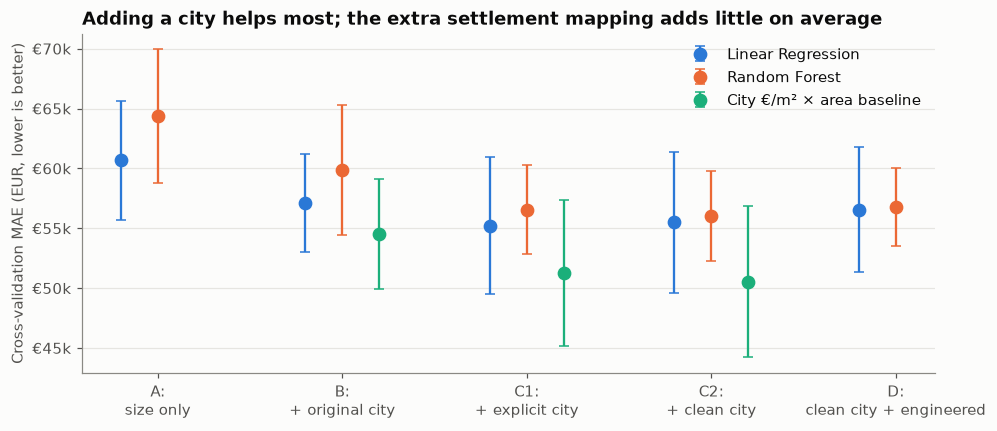

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
sets = list(vm.FEATURE_SETS)
x = np.arange(len(sets))
for off, (model, col) in zip([-0.2, 0.0, 0.2], [('Linear Regression', vplot.BLUE), ('Random Forest', vplot.ORANGE), ('City €/m² × area baseline', vplot.AQUA)]):
    d = loc[loc['model'] == model].set_index('feature_set').reindex(sets)
    ok = d['cv_mae_mean'].notna().to_numpy()
    ax.errorbar(x[ok] + off, d['cv_mae_mean'][ok], yerr=d['cv_mae_std'][ok], fmt='o', color=col, ms=8, capsize=3, lw=1.5, label=model)
ax.set_xticks(x, [s.replace(': ', ':\n') for s in sets])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro))
ax.set_ylabel('Cross-validation MAE (EUR, lower is better)')
ax.set_title('Adding a city helps most; the extra settlement mapping adds little on average')
ax.legend(loc='upper right'); ax.grid(axis='x', visible=False)
vplot.save(fig, FIG, 'model_01_location_experiment'); plt.show()

**What it means** (CV MAE; the same 1,098 rows and 5 folds everywhere):

| Inputs | Linear Regression | Random Forest | City €/m² rule |
|---|---|---|---|
| A: area + rooms | €60,682 | €64,363 | – |
| B: + original city (49% unknown) | €57,093 | €59,872 | €54,489 |
| C1: + explicit city (21% unknown) | €55,231 | €56,553 | €51,248 |
| C2: + clean city (2.4% unknown) | €55,496 | €56,061 | €50,527 |
| D: C2 + engineered features | €56,542 | €56,792 | – |

1. **Any city information helps** (A → B).
2. **Reading the explicit location text** helps much more (B → C1): €2–3k for every method.
3. **The settlement mapping** (C1 → C2) changes the **overall** average only slightly (−€721 for the city rule, −€492 for Random Forest, +€265 for Linear Regression). These differences are smaller than one standard error (≈ €2.5–2.8k), so on the full sample they cannot be told apart from noise. The next cell looks at the listings the mapping actually changed.
4. **The engineered features did not help** Linear Regression or Random Forest (D vs C2).

Better location data was not assumed to improve every metric; the effect was measured.

**What this code does:** Compares C1 (explicit city only) and C2 (+ settlement mapping) **only on the development listings that the settlement mapping located**, using the out-of-fold predictions from the same cross-validation.

**Why we need it:** The mapping changes the input of only 256 listings, so the average over all 1,098 development listings dilutes its effect. This check looks at exactly the listings it changed.

In [10]:
mapped = (dev['city_method'] == 'Reviewed settlement mapping').to_numpy()
rows = []
for model in ['Linear Regression', 'Random Forest', 'City €/m² × area baseline']:
    for fs in ['C1: + explicit city', 'C2: + clean city']:
        oof = loc_oof[(model, fs)]
        rows.append({'model': model, 'feature_set': fs,
                     f'MAE on settlement-mapped rows (n={mapped.sum()})': mean_absolute_error(y_dev[mapped], oof[mapped]),
                     f'MAE on all other rows (n={(~mapped).sum()})': mean_absolute_error(y_dev[~mapped], oof[~mapped])})
subset = pd.DataFrame(rows)
display(subset.round(0)); subset.to_csv(RES / 'location_experiment_settlement_subset.csv', index=False)

,model,feature_set,MAE on settlement-mapped rows (n=202),MAE on all other rows (n=896)
0,Linear Regression,C1: + explicit city,71360.0,51578.0
1,Linear Regression,C2: + clean city,69140.0,52414.0
2,Random Forest,C1: + explicit city,76296.0,52078.0
3,Random Forest,C2: + clean city,71593.0,52540.0
4,City €/m² × area baseline,C1: + explicit city,68790.0,47266.0
5,City €/m² × area baseline,C2: + clean city,65391.0,47155.0


**What it means:** on the 202 development listings that only the settlement mapping could locate, adding their municipality **reduced the error for all three methods**:

| Method | C1 (explicit city only) | C2 (+ settlement mapping) | Change |
|---|---|---|---|
| City €/m² rule | €68,790 | €65,391 | −5% |
| Random Forest | €76,296 | €71,593 | −6% |
| Linear Regression | €71,360 | €69,140 | −3% |

On the other 896 listings, whose inputs did not change, the error stayed about the same. So the mapping **does help the listings it locates**, but they are only 18% of the data, which is why the overall average barely moves. These listings stay harder to predict than the rest (≈ €65–72k vs ≈ €47–53k), probably because coastal settlements vary a lot within one municipality.

### 7.2 Candidate models

**My original approaches** (kept and re-evaluated on the corrected data and protocol):

| Model | How it works, in one sentence | Inputs |
|---|---|---|
| Linear Regression | Fits price = a + b×area + c×rooms + one adjustment per city | C2 |
| Random Forest | Averages 300 decision trees, each trained on a random sample of the flats | C2 |
| Random Forest + FE | The same, with the engineered features | D |
| Tuned Random Forest | Random Forest whose settings are chosen by an inner cross-validation | D |
| Tuned Extra Trees | Like a random forest, but the split points are chosen randomly, which adds more randomness | D |

**Justified additions:**

| Model | Why |
|---|---|
| Ridge (engineered) | Linear regression with a small penalty that keeps coefficients stable when features overlap (area, area², log(area)) |
| Ridge, **log target** | Prices are right-skewed and the effect of size is roughly *proportional*; modelling log(price) matches that |
| Gradient Boosting (HistGradientBoosting) | Builds trees one after another, each correcting the previous errors; often strong on tabular data |
| Gradient Boosting, **log target** | The same, on log(price) |

Settings of the untuned models are fixed in advance (not tuned on these data).

**What this code does:** Runs 5-fold cross-validation for the eight untuned candidates and records mean MAE, fold-to-fold standard deviation and training time.

**Why we need it:** Cross-validation results are the basis for choosing the model; the test set is not touched.

In [11]:
HGB = dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=20, l2_regularization=1.0, random_state=SEED)
CANDIDATES = {
    'Linear Regression': ('C2: + clean city', lambda: LinearRegression(), {}),
    'Random Forest': ('C2: + clean city', lambda: RandomForestRegressor(**RF_FIXED), {}),
    'Random Forest + FE': ('D: clean city + engineered', lambda: RandomForestRegressor(**RF_FIXED), {}),
    'Ridge (engineered)': ('D: clean city + engineered', lambda: Ridge(alpha=1.0), {'scale': True}),
    'Ridge, log target (engineered)': ('D: clean city + engineered', lambda: Ridge(alpha=1.0), {'scale': True, 'log_target': True}),
    'Gradient Boosting (engineered)': ('D: clean city + engineered', lambda: HistGradientBoostingRegressor(**HGB), {}),
    'Gradient Boosting, log target (engineered)': ('D: clean city + engineered', lambda: HistGradientBoostingRegressor(**HGB), {'log_target': True}),
}
def factory_for(name):
    fs, est, kw = CANDIDATES[name]
    return lambda: vm.make_model_pipeline(fs, est(), **kw)
for name, (fs, _, _) in CANDIDATES.items():
    run_cv(name, factory_for(name), vm.FEATURE_SETS[fs]['inputs'], fs)
    print(f"{name:45} CV MAE €{cv_rows[-1]['cv_mae_mean']:,.0f} ± {cv_rows[-1]['cv_mae_std']:,.0f}  ({cv_rows[-1]['fit_time_s']:.1f}s)")

Linear Regression                             CV MAE €55,496 ± 5,868  (0.1s)


Random Forest                                 CV MAE €56,061 ± 3,753  (4.4s)


Random Forest + FE                            CV MAE €56,792 ± 3,268  (5.1s)
Ridge (engineered)                            CV MAE €56,117 ± 5,784  (0.2s)


Ridge, log target (engineered)                CV MAE €51,595 ± 5,153  (0.2s)


Gradient Boosting (engineered)                CV MAE €59,454 ± 4,596  (3.1s)


Gradient Boosting, log target (engineered)    CV MAE €55,991 ± 3,418  (3.0s)


### 7.3 Hyperparameter tuning (nested, training data only)

I originally tuned Random Forest and Extra Trees with `GridSearchCV`. That idea is kept, with two corrections:

- **Group-aware inner folds**, so the tuning itself never sees the same flat on both sides.
- **Nested cross-validation.** Inside each of the 5 outer folds, a separate search picks the settings using that fold's training part only. The outer fold then scores the result. If tuning used all development rows and the best score were reported, that score would be **too optimistic**, because it is the best of many tries.

The search is a `RandomizedSearchCV` with 12 random settings (MAE as the target, at most 2 parallel processes). The final settings come from one more search on all development rows.

**What this code does:** Defines the search spaces and runs the nested tuning for Random Forest and Extra Trees, one model at a time. It records the best settings, the CV MAE, its standard deviation and the run time.

**Why we need it:** To find out whether tuning really helps, measured fairly.

In [12]:
SPACE = {
    'model__n_estimators': [200, 400],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4, 8],
    'model__max_features': [1.0, 0.7, 0.5, 'sqrt'],
}
TUNE_FS = 'D: clean city + engineered'
TUNE_INPUTS = vm.FEATURE_SETS[TUNE_FS]['inputs']
tuning_log, final_searches = [], {}

def make_search(est):
    return RandomizedSearchCV(vm.make_model_pipeline(TUNE_FS, est), SPACE, n_iter=12, scoring='neg_mean_absolute_error',
                              cv=GroupKFold(n_splits=4, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=1, refit=True)

for name, est in [('Tuned Random Forest', RandomForestRegressor(random_state=SEED, n_jobs=N_JOBS)),
                  ('Tuned Extra Trees', ExtraTreesRegressor(random_state=SEED, n_jobs=N_JOBS))]:
    t0 = time.perf_counter(); maes, oof, chosen_params = [], np.full(len(dev), np.nan), []
    for tr, va in CV_SPLITS:
        s = make_search(sklearn.base.clone(est)).fit(dev.loc[tr, TUNE_INPUTS], y_dev[tr], groups=dev.loc[tr, 'repeat_group'])
        oof[va] = s.predict(dev.loc[va, TUNE_INPUTS]); maes.append(mean_absolute_error(y_dev[va], oof[va]))
        chosen_params.append(s.best_params_)
    final = make_search(sklearn.base.clone(est)).fit(dev[TUNE_INPUTS], y_dev, groups=dev['repeat_group'])
    final_searches[name] = final
    seconds = time.perf_counter() - t0
    cv_rows.append({'model': name, 'feature_set': TUNE_FS, 'cv_mae_mean': np.mean(maes), 'cv_mae_std': np.std(maes, ddof=1),
                    'n_folds': 5, 'fit_time_s': seconds, 'split_id': SPLIT_ID, **{f'fold_{i}': m for i, m in enumerate(maes)}})
    oof_store[name] = oof
    tuning_log.append({'model': name, 'search_space': json.dumps(SPACE), 'best_params_final': json.dumps(final.best_params_, default=str),
                       'nested_cv_mae_mean': np.mean(maes), 'nested_cv_mae_std': np.std(maes, ddof=1),
                       'inner_best_score_final': -final.best_score_, 'fold_best_params': json.dumps(chosen_params, default=str),
                       'time_s': seconds})
    print(f"{name}: nested CV MAE €{np.mean(maes):,.0f} ± {np.std(maes, ddof=1):,.0f} | final settings {final.best_params_} | {seconds:.0f}s")
tuning = pd.DataFrame(tuning_log); tuning.to_csv(RES / 'tuning_log.csv', index=False)
display(tuning[['model', 'nested_cv_mae_mean', 'nested_cv_mae_std', 'inner_best_score_final', 'time_s']].round(0))

Tuned Random Forest: nested CV MAE €55,373 ± 4,609 | final settings {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 10} | 269s


Tuned Extra Trees: nested CV MAE €55,146 ± 5,351 | final settings {'model__n_estimators': 400, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': None} | 176s


,model,nested_cv_mae_mean,nested_cv_mae_std,inner_best_score_final,time_s
0,Tuned Random Forest,55373.0,4609.0,55820.0,269.0
1,Tuned Extra Trees,55146.0,5351.0,55105.0,176.0


**What it means:**

| Model | Nested CV MAE | Time | Final settings |
|---|---|---|---|
| Tuned Random Forest | €55,373 ± 4,609 | 180 s | 200 trees, max depth 10, min split 10, `sqrt` features |
| Tuned Extra Trees | €55,146 ± 5,351 | 142 s | 400 trees, no depth limit, min split 10, `sqrt` features |

Tuning improved on the untuned Random Forest with the same features (€56,792) by about €1.4–1.6k. That is **less than one standard error**, so tuning gives at most a small gain here.

The settings chosen in different outer folds varied (see `fold_best_params` in `docs/results/tuning_log.csv`). That is another sign that several settings perform about equally well.

## 8. Evaluation & comparison

### 8.1 Cross-validation comparison and model choice

**What this code does:** Puts all cross-validation results in one table, adds each model's complexity rank, and applies the selection rule fixed in Section 4.1 (`vm.select_model`).

**Why we need it:** This is where the final model is chosen, using development data only.

In [13]:
cv = pd.DataFrame(cv_rows)
cv['complexity'] = cv['model'].map(PROTOCOL['complexity_rank'])
assert cv['split_id'].nunique() == 1, 'All models must use the same CV folds'
cv['improvement_vs_median_baseline_%'] = 100 * (1 - cv['cv_mae_mean'] / cv.loc[cv['model'] == 'Median baseline', 'cv_mae_mean'].iloc[0])
cv['improvement_vs_city_baseline_%'] = 100 * (1 - cv['cv_mae_mean'] / cv.loc[cv['model'] == 'City €/m² × area baseline', 'cv_mae_mean'].iloc[0])
cv = cv.sort_values('cv_mae_mean').reset_index(drop=True)
cv.to_csv(RES / 'cv_results.csv', index=False)
display(cv[['model', 'feature_set', 'cv_mae_mean', 'cv_mae_std', 'complexity', 'improvement_vs_city_baseline_%', 'fit_time_s']].round(1))
selection = vm.select_model(cv)
CHOSEN = selection['chosen']
(RES / 'selection.json').write_text(json.dumps(selection, indent=2, ensure_ascii=False), encoding='utf-8')
print(f"Best CV MAE: {selection['best_cv_model']} (€{selection['best_cv_mae']:,.0f}); 1 standard error = €{selection['standard_error']:,.0f}")
print(f"Models within 1 SE: {selection['eligible']}")
print(f'CHOSEN MODEL: {CHOSEN}')

,model,feature_set,cv_mae_mean,cv_mae_std,complexity,improvement_vs_city_baseline_%,fit_time_s
0,City €/m² × area baseline,C2: + clean city,50526.9,6297.1,1,0.0,0.0
1,"Ridge, log target (engineered)",D: clean city + engineered,51594.9,5153.2,2,-2.1,0.2
2,Tuned Extra Trees,D: clean city + engineered,55145.8,5350.9,4,-9.1,176.4
3,Tuned Random Forest,D: clean city + engineered,55372.9,4609.2,4,-9.6,268.7
4,Linear Regression,C2: + clean city,55495.9,5867.8,2,-9.8,0.1
5,"Gradient Boosting, log target (engineered)",D: clean city + engineered,55990.9,3418.2,3,-10.8,3.0
6,Random Forest,C2: + clean city,56061.3,3752.6,3,-11.0,4.4
7,Ridge (engineered),D: clean city + engineered,56117.1,5784.3,2,-11.1,0.2
8,Random Forest + FE,D: clean city + engineered,56792.3,3267.6,3,-12.4,5.1
9,Gradient Boosting (engineered),D: clean city + engineered,59454.5,4596.0,3,-17.7,3.1


Best CV MAE: City €/m² × area baseline (€50,527); 1 standard error = €2,816
Models within 1 SE: ['City €/m² × area baseline', 'Ridge, log target (engineered)']
CHOSEN MODEL: City €/m² × area baseline


**What this code does:** Draws the cross-validation MAE of every model, with error bars (±1 standard deviation across folds) and the 1-standard-error tolerance line.

**Why we need it:** Shows how close the models are, and why the rule picks the chosen model.

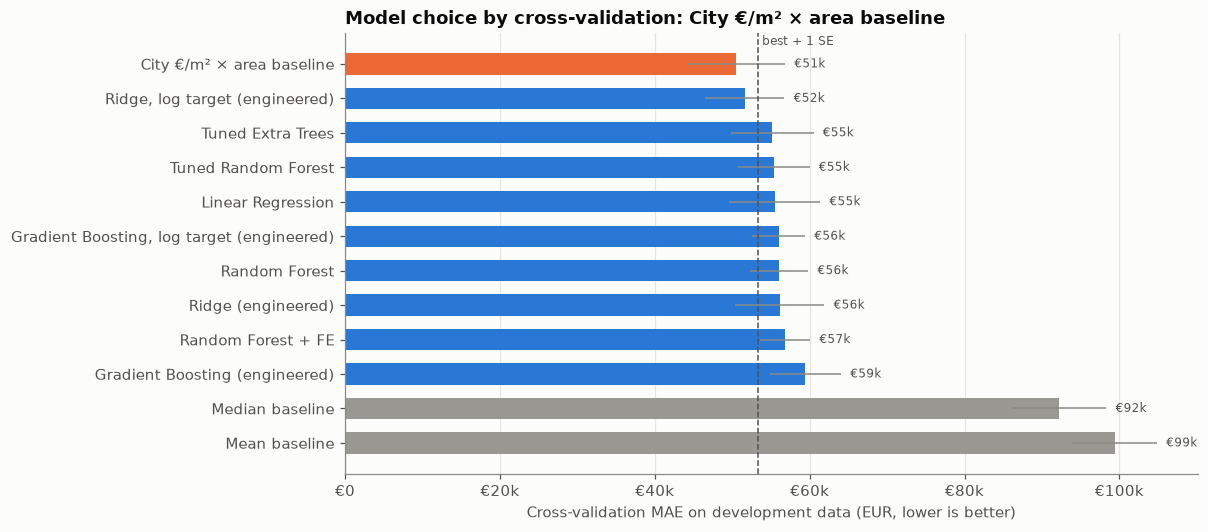

In [14]:
d = cv.sort_values('cv_mae_mean', ascending=False)
fig, ax = plt.subplots(figsize=(10, 5.2))
colors = [vplot.ORANGE if m == CHOSEN else (vplot.GRAY if 'baseline' in m else vplot.BLUE) for m in d['model']]
ax.barh(d['model'], d['cv_mae_mean'], xerr=d['cv_mae_std'], color=colors, height=0.62, error_kw=dict(ecolor=vplot.INK_3, lw=1))
ax.axvline(selection['tolerance'], color=vplot.INK_2, ls='--', lw=1)
ax.text(selection['tolerance'], len(d) - 0.45, ' best + 1 SE', color=vplot.INK_2, fontsize=8)
for y, (v, sd) in enumerate(zip(d['cv_mae_mean'], d['cv_mae_std'])):
    ax.text(v + sd + 1200, y, vplot.euro(v), va='center', color=vplot.INK_2, fontsize=8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro))
ax.set_xlabel('Cross-validation MAE on development data (EUR, lower is better)')
ax.set_title(f'Model choice by cross-validation: {CHOSEN}')
ax.grid(axis='y', visible=False)
vplot.save(fig, FIG, 'model_02_cv_comparison'); plt.show()

**What it means:**
- The lowest cross-validation MAE belongs to the **city €/m² × area rule** (€50,527).
- One standard error is €2,816, so every method with a CV MAE up to **€53,343** counts as "equally good". Only the **log-target Ridge** (€51,595) qualifies.
- The rule prefers the simpler method: the city rule has complexity 1, Ridge has 2.
- **Chosen: the city €/m² × area rule.** It would also have been chosen without the simplicity step, because its CV MAE was the lowest.

This is a legitimate and useful result. With only area, rooms and city available, a transparent rule a valuer can check by hand is as accurate on average as the machine learning models tested. The ML models do not have the extra information about each flat (exact location, condition, view, floor) that they would need to do clearly better.

### 8.2 Final test (used once, after the choice)

**What this code does:** Trains every candidate and baseline on **all** development rows, predicts the test rows once, and computes MAE, RMSE, R², median absolute error and MAPE in euros. The chosen model is marked.

**Why we need it:** This reports how the methods do on flats none of them saw. The choice is already fixed, so these numbers cannot influence it.

In [15]:
def build(name):
    if name in BASELINES:
        factory, inputs, _ = BASELINES[name]; return factory(), inputs
    if name in final_searches:
        return final_searches[name].best_estimator_, TUNE_INPUTS
    fs = CANDIDATES[name][0]
    return factory_for(name)(), vm.FEATURE_SETS[fs]['inputs']

test_pred, fitted, test_rows = {}, {}, []
for name in cv['model']:
    model, inputs = build(name)
    if name not in final_searches:
        model.fit(dev[inputs], y_dev)
    fitted[name] = (model, inputs)
    test_pred[name] = model.predict(test[inputs])
    test_rows.append({'model': name, **vm.regression_metrics(y_test, test_pred[name])})
res = pd.DataFrame(test_rows).merge(cv[['model', 'feature_set', 'cv_mae_mean', 'cv_mae_std']], on='model')
base_mae = res.set_index('model')['MAE']
res['improvement_vs_mean_baseline_%'] = 100 * (1 - res['MAE'] / base_mae['Mean baseline'])
res['improvement_vs_city_baseline_%'] = 100 * (1 - res['MAE'] / base_mae['City €/m² × area baseline'])
res['chosen'] = res['model'].eq(CHOSEN)
res = res.sort_values('cv_mae_mean').reset_index(drop=True)
res.to_csv(RES / 'test_results.csv', index=False)
pd.DataFrame({'record_id': test['record_id'], 'actual_eur': y_test, **{m: p for m, p in test_pred.items()}}).to_csv(RES / 'test_predictions.csv', index=False)
assert (res['RMSE'] >= res['MAE'] - 1e-6).all()
display(res[['model', 'feature_set', 'cv_mae_mean', 'cv_mae_std', 'MAE', 'RMSE', 'R2', 'MedianAE', 'MAPE_%', 'improvement_vs_city_baseline_%', 'chosen']]
        .round({'cv_mae_mean': 0, 'cv_mae_std': 0, 'MAE': 0, 'RMSE': 0, 'R2': 3, 'MedianAE': 0, 'MAPE_%': 1, 'improvement_vs_city_baseline_%': 1}))

,model,feature_set,cv_mae_mean,cv_mae_std,MAE,RMSE,R2,MedianAE,MAPE_%,improvement_vs_city_baseline_%,chosen
0,City €/m² × area baseline,C2: + clean city,50527.0,6297.0,57478.0,125228.0,0.469,28532.0,20.9,0.0,True
1,"Ridge, log target (engineered)",D: clean city + engineered,51595.0,5153.0,56847.0,120632.0,0.507,29148.0,20.9,1.1,False
2,Tuned Extra Trees,D: clean city + engineered,55146.0,5351.0,56284.0,103397.0,0.638,33191.0,22.9,2.1,False
3,Tuned Random Forest,D: clean city + engineered,55373.0,4609.0,58915.0,110459.0,0.587,35069.0,24.0,-2.5,False
4,Linear Regression,C2: + clean city,55496.0,5868.0,60675.0,124211.0,0.478,33150.0,24.8,-5.6,False
5,"Gradient Boosting, log target (engineered)",D: clean city + engineered,55991.0,3418.0,54913.0,114105.0,0.559,27270.0,21.3,4.5,False
6,Random Forest,C2: + clean city,56061.0,3753.0,56490.0,103983.0,0.634,30347.0,22.8,1.7,False
7,Ridge (engineered),D: clean city + engineered,56117.0,5784.0,59751.0,121030.0,0.504,32727.0,23.5,-4.0,False
8,Random Forest + FE,D: clean city + engineered,56792.0,3268.0,55373.0,103255.0,0.639,29538.0,22.7,3.7,False
9,Gradient Boosting (engineered),D: clean city + engineered,59454.0,4596.0,56714.0,108166.0,0.604,31238.0,23.0,1.3,False


**What this code does:** Draws the test MAE of all methods next to their cross-validation MAE.

**Why we need it:** If the two disagree strongly, the cross-validation estimate was unreliable. If they agree, it was a good guide.

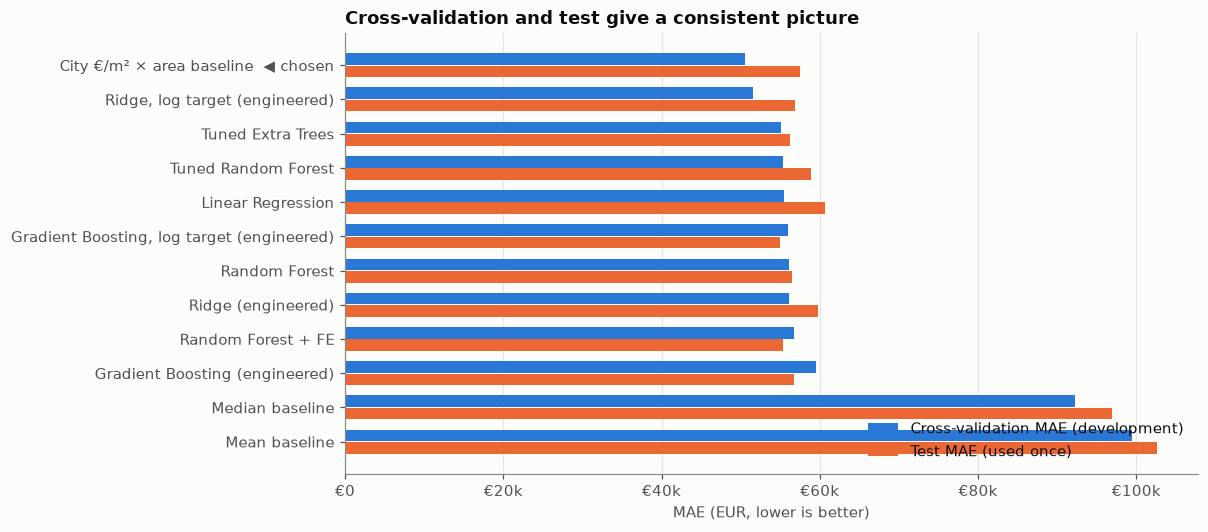

In [16]:
d = res.sort_values('cv_mae_mean', ascending=False)
fig, ax = plt.subplots(figsize=(10, 5.2))
y = np.arange(len(d))
ax.barh(y + 0.18, d['cv_mae_mean'], height=0.34, color=vplot.BLUE, label='Cross-validation MAE (development)')
ax.barh(y - 0.18, d['MAE'], height=0.34, color=vplot.ORANGE, label='Test MAE (used once)')
ax.set_yticks(y, [m + ('  ◀ chosen' if m == CHOSEN else '') for m in d['model']])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro))
ax.set_xlabel('MAE (EUR, lower is better)'); ax.set_title('Cross-validation and test give a consistent picture')
ax.legend(loc='lower right'); ax.grid(axis='y', visible=False)
vplot.save(fig, FIG, 'model_03_test_comparison'); plt.show()

**What it means** (278 test listings, never used for any choice):

| Method | Test MAE | RMSE | R² | Median abs. error |
|---|---|---|---|---|
| **City €/m² × area (chosen)** | **€57,478** | €125,228 | 0.469 | €28,532 |
| Gradient Boosting, log target | €54,913 | €114,105 | 0.559 | €27,270 |
| Random Forest + FE | €55,373 | €103,255 | 0.639 | €29,538 |
| Tuned Extra Trees | €56,284 | €103,397 | 0.638 | €33,191 |
| Ridge, log target | €56,847 | €120,632 | 0.507 | €29,148 |
| Linear Regression | €60,675 | €124,211 | 0.478 | €33,150 |
| Mean-price baseline | €102,610 | €172,165 | −0.004 | €78,903 |

- **The chosen rule improves MAE by 44%** over the mean-price baseline (41% over the median baseline).
- **The ranking among close candidates is not stable.** On the test set, Gradient Boosting (log target) and the forests have a €1–3k lower MAE than the chosen rule; in cross-validation they were €5–6k worse. Differences of this size are within the noise of a 278-row test set. Choosing the test winner now would make the test score optimistic, so **the choice stays as decided**.
- **Large errors: corrected statement.**
  - On *this test sample*, the tree models have a lower RMSE (≈ €103k vs €125k) and higher R² (0.64 vs 0.47) than the rule.
  - The later research extension checked this with cross-validation on the 1,098 development listings, and it was **not confirmed**: there the Random Forest has a *higher* RMSE and lower R² than the rule (pooled out-of-fold R² 0.563 vs 0.582).
  - The apparent advantage is therefore a property of this particular test sample. It must not be presented as a general finding.
- **CV vs test.** Test errors are higher than CV errors for most methods (e.g. €57.5k vs €50.5k for the chosen rule). The test set does not contain more expensive flats than the development data (4.3% vs 4.6% priced ≥ €500k). But in a sample of 278, a few large misses move the average a lot: the two largest errors alone (two Budva flats, Section 9) add about €7,800 to the chosen rule's test MAE.
- **R² is not accuracy.** 0.469 means the rule explains about 47% of the price differences between flats. It does not mean the estimates are "47% correct".

### 8.3 Location experiment on the test set

**What this code does:** Evaluates the location experiment (feature sets A–D) once on the test rows, with the same models.

**Why we need it:** To check whether the cross-validation conclusion about location also holds on unseen flats.

In [17]:
loc_test = []
for fs, spec in vm.FEATURE_SETS.items():
    for label, est in [('Linear Regression', LinearRegression()), ('Random Forest', RandomForestRegressor(**RF_FIXED))]:
        m = vm.make_model_pipeline(fs, sklearn.base.clone(est)).fit(dev[spec['inputs']], y_dev)
        loc_test.append({'feature_set': fs, 'model': label, **vm.regression_metrics(y_test, m.predict(test[spec['inputs']]))})
for col, fs in [('city_original', 'B: + original city'), ('city_explicit', 'C1: + explicit city'), ('city_clean', 'C2: + clean city')]:
    m = vm.CityPricePerM2Baseline(col).fit(dev[['area_m2', col]], y_dev)
    loc_test.append({'feature_set': fs, 'model': 'City €/m² × area baseline', **vm.regression_metrics(y_test, m.predict(test[['area_m2', col]]))})
loc_test = pd.DataFrame(loc_test)
loc_test.to_csv(RES / 'location_experiment_test.csv', index=False)
display(loc_test.pivot(index='feature_set', columns='model', values='MAE').reindex(list(vm.FEATURE_SETS)).round(0))
display(loc_test.pivot(index='feature_set', columns='model', values='R2').reindex(list(vm.FEATURE_SETS)).round(3))

model,City €/m² × area baseline,Linear Regression,Random Forest
feature_set,,,
A: size only,NaN,65539.0,64060.0
B: + original city,60243.0,62116.0,62402.0
C1: + explicit city,58261.0,61090.0,56642.0
C2: + clean city,57478.0,60675.0,56490.0
D: clean city + engineered,NaN,59775.0,55373.0


model,City €/m² × area baseline,Linear Regression,Random Forest
feature_set,,,
A: size only,NaN,0.425,0.509
B: + original city,0.433,0.461,0.506
C1: + explicit city,0.476,0.477,0.640
C2: + clean city,0.469,0.478,0.634
D: clean city + engineered,NaN,0.508,0.639


**What it means:** the test set confirms the CV picture.
- Location information clearly lowers the error:
  - Random Forest: €64,060 (size only) → €62,402 (original city) → €56,642 (explicit) → **€56,490** (clean);
  - city rule: €60,243 → €58,261 → **€57,478**.
- **R²** of the Random Forest rises from 0.506 with the original city field to **0.634** with the clean city.
- The settlement mapping step (C1 → C2) is again small but in the same direction for all three methods (−€152 to −€783).

### 8.4 Sensitivity: including the four luxury listings (decision D5)

**What this code does:** Trains the chosen model a second time with the 4 valid luxury listings that fall in the development data, and compares both versions on the **same** primary test rows. It also predicts the 4 luxury listings with the primary model, which never saw them.

**Why we need it:** To show honestly what the price and area ranges change. A valid luxury flat is not an error, so it matters how the model treats it.

In [18]:
model_p, inputs = fitted[CHOSEN]
model_e, _ = build(CHOSEN)
if CHOSEN in final_searches:
    model_e = sklearn.base.clone(model_p)
model_e.fit(dev_ext[inputs], dev_ext['price_eur'])
sens = pd.DataFrame([
    {'training population': f'primary ({len(dev)} rows)', **vm.regression_metrics(y_test, model_p.predict(test[inputs]))},
    {'training population': f'primary + luxury in development ({len(dev_ext)} rows)', **vm.regression_metrics(y_test, model_e.predict(test[inputs]))},
])
display(sens.round({'MAE': 0, 'RMSE': 0, 'R2': 3, 'MedianAE': 0, 'MAPE_%': 1}))
lux_pred = lux[['record_id', 'split', 'city_clean', 'area_m2', 'rooms', 'price_eur']].copy()
lux_pred['predicted_by_primary_model'] = model_p.predict(lux[inputs])
lux_pred['error_eur'] = lux_pred['predicted_by_primary_model'] - lux_pred['price_eur']
display(lux_pred.drop(columns='record_id').round(0))
sens.to_csv(RES / 'sensitivity_luxury.csv', index=False); lux_pred.to_csv(RES / 'luxury_predictions.csv', index=False)

,training population,MAE,RMSE,R2,MedianAE,MAPE_%
0,primary (1098 rows),57478.0,125228.0,0.469,28532.0,20.9
1,primary + luxury in development (1101 rows),57468.0,125188.0,0.469,28332.0,20.9


,split,city_clean,area_m2,rooms,price_eur,predicted_by_primary_model,error_eur
128,development,Podgorica,450.0,4.0,1500000.0,1265625.0,-234375.0
511,test,Budva,400.0,3.0,950000.0,1414578.0,464578.0
520,development,Budva,347.0,3.0,3300000.0,1227146.0,-2072854.0
1145,development,Unknown,353.0,3.0,850000.0,1059000.0,209000.0


**What it means:**
- Only 3 of the 4 luxury listings fall in the development data. Adding them changes the chosen rule's test result by **€10** (MAE €57,478 → €57,468), because a median per city is barely moved by 3 extra listings. **Decision D5 (the earlier ranges) therefore does not drive the results.**
- The rule handles these flats poorly in both directions:

| Flat | Asking price | Predicted | Error |
|---|---|---|---|
| Budva, 347 m² | €3.3M | €1.23M | −€2.07M |
| Budva, 400 m² | €950k | €1.41M | +€465k |
| Podgorica, 450 m² | €1.5M | €1.27M | −€234k |
| Unknown city, 353 m² | €850k | €1.06M | +€209k |

  For flats this large, price per m² differs a lot between buildings, and city × area cannot capture that. **Estimates for very large or luxury flats should not be trusted.**

### 8.5 Comparison with the original notebooks

**What this code does:** Shows the results saved in my original notebooks next to this notebook's results, with clear labels.

**Why we need it:** To document progress honestly. The two sets of numbers come from **different data and different test rows**, so the difference is **not** a direct measure of model improvement.

In [19]:
original = pd.DataFrame([
    ['Mean baseline (original)', 107905, 176182, -0.00], ['Linear Regression (original)', 68637, 125650, 0.49],
    ['Random Forest (original, leaf=2)', 71129, 137105, 0.39], ['RF + FE (original, leaf=2)', 71302, 136262, 0.40],
    ['Optimized RF (original)', 71179, 136276, 0.40], ['Extra Trees, tuned (original)', 67535, 121970, 0.52],
], columns=['model', 'MAE', 'RMSE', 'R2'])
original['data'] = '1,473 rows incl. 36 rents and 47 re-posts; 703 unknown cities; random split; 295 test rows'
now = res.loc[res['model'].isin(['Mean baseline', 'Linear Regression', 'Random Forest', 'Random Forest + FE', 'Tuned Random Forest', 'Tuned Extra Trees', CHOSEN]),
              ['model', 'MAE', 'RMSE', 'R2']].assign(data=f'{len(primary):,} cleaned rows; group-aware split; {len(test)} test rows')
display(pd.concat([original, now]).round({'MAE': 0, 'RMSE': 0, 'R2': 3}))

,model,MAE,RMSE,R2,data
0,Mean baseline (original),107905.0,176182.0,-0.000,"1,473 rows incl. 36 rents and 47 re-posts; 703..."
1,Linear Regression (original),68637.0,125650.0,0.490,"1,473 rows incl. 36 rents and 47 re-posts; 703..."
2,"Random Forest (original, leaf=2)",71129.0,137105.0,0.390,"1,473 rows incl. 36 rents and 47 re-posts; 703..."
3,"RF + FE (original, leaf=2)",71302.0,136262.0,0.400,"1,473 rows incl. 36 rents and 47 re-posts; 703..."
4,Optimized RF (original),71179.0,136276.0,0.400,"1,473 rows incl. 36 rents and 47 re-posts; 703..."
5,"Extra Trees, tuned (original)",67535.0,121970.0,0.520,"1,473 rows incl. 36 rents and 47 re-posts; 703..."
0,City €/m² × area baseline,57478.0,125228.0,0.469,"1,376 cleaned rows; group-aware split; 278 tes..."
2,Tuned Extra Trees,56284.0,103397.0,0.638,"1,376 cleaned rows; group-aware split; 278 tes..."
3,Tuned Random Forest,58915.0,110459.0,0.587,"1,376 cleaned rows; group-aware split; 278 tes..."
4,Linear Regression,60675.0,124211.0,0.478,"1,376 cleaned rows; group-aware split; 278 tes..."


The original numbers were reproduced exactly during the audit, so they are real. They cannot be compared directly with the new ones:
- the old test set contained **rentals** (€2,000 "flats"), **duplicates that could appear in both training and test**, and very different city information;
- the new test set contains none of these.

The fair before/after comparison is the **controlled location experiment** (7.1 and 8.3), which changes one thing at a time on the same rows.

### 8.6 Save and reload the final model

**What this code does:** Saves the chosen pipeline (feature engineering, preprocessing and model together) with `joblib`, loads it again, and checks that it gives identical predictions. It also records the library versions.

**Why we need it:** A saved model is only useful if it reloads and predicts the same. A joblib file depends on the library versions, so they are recorded next to it. Only model files created by this notebook are loaded; joblib files from unknown sources can run arbitrary code.

In [20]:
final_model, final_inputs = fitted[CHOSEN]
model_path = MODELS / 'valora_final_model.joblib'
joblib.dump(final_model, model_path)
reloaded = joblib.load(model_path)
same = np.allclose(reloaded.predict(test[final_inputs]), test_pred[CHOSEN], rtol=0, atol=1e-6)
meta = {'model': CHOSEN, 'inputs': final_inputs, 'trained_on_rows': len(dev), 'reload_predictions_identical': bool(same),
        'python': _platform.python_version(), 'scikit-learn': sklearn.__version__, 'pandas': pd.__version__,
        'numpy': np.__version__, 'joblib': joblib.__version__, 'note': 'load only this trusted file; needs src/ on the Python path (valora_model / valora_prep)'}
(MODELS / 'valora_final_model_meta.json').write_text(json.dumps(meta, indent=2), encoding='utf-8')
(RES / 'final_model_meta.json').write_text(json.dumps(meta, indent=2), encoding='utf-8')
assert same
print(json.dumps(meta, indent=2))

{
  "model": "City \u20ac/m\u00b2 \u00d7 area baseline",
  "inputs": [
    "area_m2",
    "city_clean"
  ],
  "trained_on_rows": 1098,
  "reload_predictions_identical": true,
  "python": "3.11.9",
  "scikit-learn": "1.9.1",
  "pandas": "3.1.1",
  "numpy": "2.4.6",
  "joblib": "1.6.0",
  "note": "load only this trusted file; needs src/ on the Python path (valora_model / valora_prep)"
}


### 8.7 Additional research after the main analysis (summary)

After the main analysis, three exploratory phases tested whether the result could be improved or extended. They used **only the development listings and the same folds**. The full records are in `docs/research/`.

| Phase | What was tried | Result |
|---|---|---|
| Research extension | Hybrid "rule + learned correction" (additive, multiplicative, log; Ridge and Gradient Boosting); €/m² as target; estimating missing room counts; city-specific area effects; neighbourhood information | No reliable gain over the city €/m² rule. Nested tuning chose near-zero corrections. Only neighbourhood information gave a weak, mostly-Podgorica signal |
| Opportunity audit | Clustering, classification targets, house prices, rents, anomaly detection, time series | Not justified by these data (too few non-price features; no land area for houses; 37 rentals; no dates). Prediction ranges ranked first |
| Uncertainty research | 8 interval methods: empirical baseline, three conformal variants, linear and gradient-boosting quantile regression, two CQR variants | Linear quantile regression (G3a) chosen by a pre-registered rule; used in 8.8–8.9 |

**What this code does:** Loads the research-extension results table and shows every configuration's CV MAE next to the city rule. It also identifies the best machine-learning candidate in this notebook's own comparison (section 8.1).

**Why we need it:** To show in one place why more complex models were not adopted for the point estimate.

In [21]:
ext = pd.read_csv(ROOT / 'docs' / 'research' / 'research_extension' / 'results' / 'all_results.csv')
ext['description'] = ext['notes'].str.split(' | chosen', regex=False).str[0]
display(ext.sort_values('cv_mae_mean')[['id', 'description', 'cv_mae_mean', 'cv_mae_std', 'paired_diff_vs_R0_mean', 'paired_diff_vs_R0_se', 'oof_r2_pooled']]
        .round({'cv_mae_mean': 0, 'cv_mae_std': 0, 'paired_diff_vs_R0_mean': 0, 'paired_diff_vs_R0_se': 0, 'oof_r2_pooled': 3}))
best_ml = cv[~cv['model'].str.contains('baseline')].sort_values('cv_mae_mean').iloc[0]
print(f"Best ML candidate in section 8.1: {best_ml['model']} (CV MAE €{best_ml['cv_mae_mean']:,.0f} ± {best_ml['cv_mae_std']:,.0f}) vs city rule €{cv.loc[cv['model'] == CHOSEN, 'cv_mae_mean'].iloc[0]:,.0f}")

,id,description,cv_mae_mean,cv_mae_std,paired_diff_vs_R0_mean,paired_diff_vs_R0_se,oof_r2_pooled
15,C1,Combination: D1 + neighbourhood (= F1),49502.0,4452.0,-1025.0,864.0,0.569
14,F1,D1 + one-hot city|neighbourhood (≥10 training ...,49502.0,4452.0,-1025.0,864.0,0.569
0,R0,City median €/m² × area (final model),50527.0,6297.0,0.0,0.0,0.582
8,B3,Rule × exp(log Ridge correction) (nested α),50731.0,5768.0,204.0,287.0,0.579
4,A2,"Ridge on log €/m², set D",51551.0,5215.0,1024.0,598.0,0.568
1,R1,"Ridge, log target, set D",51595.0,5153.0,1068.0,627.0,0.566
11,D2,Rooms imputed by training area-quintile median,51720.0,5203.0,1193.0,624.0,0.562
10,D1,"Control: R1 family, median rooms before engine...",51731.0,5184.0,1204.0,647.0,0.561
12,D3,Rooms = expected value from P(rooms | log area...,51736.0,5176.0,1209.0,627.0,0.562
7,B2,Rule × multiplicative Ridge correction (nested α),51818.0,6572.0,1291.0,357.0,0.591


Best ML candidate in section 8.1: Ridge, log target (engineered) (CV MAE €51,595 ± 5,153) vs city rule €50,527


**What it means:**
- **Within this notebook (section 8.1)**, the best machine-learning candidate is the **log-target Ridge** (CV MAE €51,595 ± 5,153). That is €1,068 worse than the rule (€50,527 ± 6,297) and within one standard error.
- **In the research extension** (same folds):
  - **Hybrids** that start from the rule and learn a correction (B1–B4) did not beat it. Nested tuning chose the strongest penalty offered, i.e. "almost no correction".
  - **Modelling €/m²** (A1–A3) gave no gain. Log €/m² is mathematically almost the same model as log price.
  - **Estimating missing room counts** (D2, D3): rooms can be estimated from area (≈ 0.3 rooms error), but this added nothing to the price estimate.
  - **City-specific area effects** (E1) did not help.
  - **Neighbourhood information** (F1, mostly Podgorica) was the only addition with a gain larger than its uncertainty (CV MAE €49,502, −€1,025 vs the rule, SE €864). It is exploratory and depends on one platform's capped sample, so it is **not** used in the final method.
- **Why the complex models add little:** with only area, rooms and city, the city's typical €/m² already captures most of what can be learned. The remaining error comes from things the data do not contain: condition, view, floor, exact location and building quality.

### 8.8 Prediction intervals: how certain are the estimates? (cross-validation)

A single estimated price hides how uncertain it is. A **prediction interval** gives a range that should contain the **asking price of one new flat** with a chosen probability, here **80%** (and 90% as a secondary level).

Two methods are compared:

| Method | How the range is built | Central estimate |
|---|---|---|
| **G1, empirical baseline** | The 10th–90th percentile of €/m² in the city (training listings) × area | City median €/m² × area (the final point method) |
| **G3a, linear quantile regression** | Three linear models on log price predict the 10th, 50th and 90th **percentile** (quantile) of the price, from log(area), rooms and city | The 50th percentile (median) of the quantile model |

- Both use the **same 5 group-aware folds** on the 1,098 development listings.
- G3a was chosen among 8 interval methods in the uncertainty research, by a rule fixed in advance: acceptable coverage (77–83%), then the best interval score, then simplicity.
- The code below re-computes G1 and G3a and checks that the numbers are **identical** to the research phase.

**What this code does:** Runs G1 and G3a at 80% and 90% on the same folds, stores every out-of-fold interval, computes the metrics per fold, and checks the result against the research phase.

**Why we need it:** To reproduce the interval results inside the final workflow, not only cite them.

In [22]:
LEVELS = {0.80: 0.20, 0.90: 0.10}
IOOF = {(m, lv): {k: np.full(len(dev), np.nan) for k in ('lo', 'hi', 'c')} for m in vi.METHODS for lv in LEVELS}
irows = []
for m, cls in vi.METHODS.items():
    for lv, alpha in LEVELS.items():
        for k, (tr, va) in enumerate(CV_SPLITS):
            lo, hi, c = cls(alpha).fit(dev.iloc[tr]).predict(dev.iloc[va])
            for key, v in zip(('lo', 'hi', 'c'), (lo, hi, c)):
                IOOF[(m, lv)][key][va] = v
            irows.append({'method': m, 'level': lv, 'fold': k, **vi.interval_metrics(y_dev[va], lo, hi, c, alpha)})
IF = pd.DataFrame(irows); IF.to_csv(RES / 'interval_cv_fold_metrics.csv', index=False)
icv = IF.groupby(['method', 'level']).agg(coverage=('coverage', 'mean'), coverage_std=('coverage', 'std'), mean_width=('mean_width', 'mean'),
                                         median_width=('median_width', 'mean'), median_rel_width=('median_rel_width', 'mean'),
                                         interval_score=('interval_score', 'mean'), interval_score_std=('interval_score', 'std'),
                                         pinball=('pinball', 'mean'), central_mae=('central_mae', 'mean'),
                                         miss_above_pct=('miss_above_%', 'mean'), miss_below_pct=('miss_below_%', 'mean')).reset_index()
icv.to_csv(RES / 'interval_cv_summary.csv', index=False)
display(icv.round({'coverage': 3, 'coverage_std': 3, 'mean_width': 0, 'median_width': 0, 'median_rel_width': 3, 'interval_score': 0,
                   'interval_score_std': 0, 'pinball': 0, 'central_mae': 0, 'miss_above_pct': 1, 'miss_below_pct': 1}))
ref = pd.read_csv(ROOT / 'docs' / 'research' / 'uncertainty_research' / 'results' / 'fold_metrics.csv')
for m in vi.METHODS:
    for lv in LEVELS:
        a = IF[(IF.method == m) & (IF.level == lv)].sort_values('fold'); b = ref[(ref.method == m) & (ref.level == lv)].sort_values('fold')
        assert np.allclose(a['interval_score'], b['interval_score'], rtol=1e-9) and np.allclose(a['coverage'], b['coverage'])
print('G1 and G3a fold results are identical to the uncertainty research phase.')
pd.DataFrame({'record_id': dev['record_id'], 'actual_eur': y_dev, **{f'{m}_{int(lv*100)}_{k}': v for (m, lv), d in IOOF.items() for k, v in d.items()}}) \
  .to_csv(RES / 'interval_cv_oof.csv', index=False)

,method,level,coverage,coverage_std,mean_width,median_width,median_rel_width,interval_score,interval_score_std,pinball,central_mae,miss_above_pct,miss_below_pct
0,G1,0.8,0.779,0.030,145339.0,116324.0,0.580,261265.0,41622.0,13063.0,50527.0,11.1,11.0
1,G1,0.9,0.879,0.021,190863.0,151771.0,0.785,337273.0,79274.0,8432.0,50527.0,6.2,5.9
2,G3a,0.8,0.789,0.036,155866.0,118156.0,0.643,250429.0,32919.0,12521.0,50855.0,10.8,10.3
3,G3a,0.9,0.890,0.018,215699.0,154837.0,0.854,311616.0,56254.0,7790.0,50855.0,5.5,5.6


G1 and G3a fold results are identical to the uncertainty research phase.


**What this code does:** Draws coverage against median relative width for G1 and G3a at both levels, with the other six methods from the uncertainty research in grey for context.

**Why we need it:** The basic trade-off: a wider range covers more flats but says less. A good method reaches the target coverage with the narrowest range.

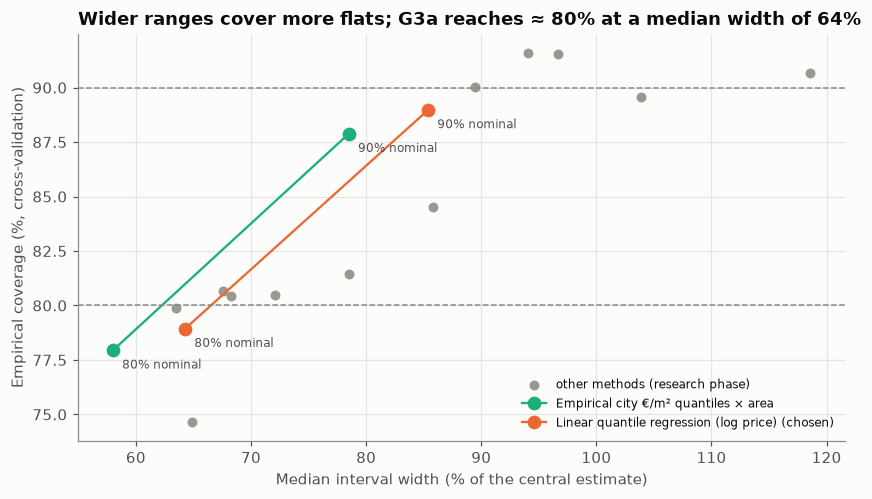

In [23]:
other = pd.concat([pd.read_csv(ROOT / 'docs' / 'research' / 'uncertainty_research' / 'results' / f'summary_{l}.csv').assign(level=l / 100) for l in (80, 90)])
other = other[~other['method'].isin(vi.METHODS)]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.scatter(100 * other['median_rel_width'], 100 * other['coverage'], color=vplot.GRAY, s=30, label='other methods (research phase)')
for m, col in [('G1', vplot.AQUA), ('G3a', vplot.ORANGE)]:
    d = icv[icv['method'] == m]
    ax.plot(100 * d['median_rel_width'], 100 * d['coverage'], '-o', color=col, ms=8, lw=1.5, label=vi.LABELS[m] + (' (chosen)' if m == 'G3a' else ''))
    for _, r in d.iterrows():
        ax.annotate(f"{int(round(r.level * 100))}% nominal", (100 * r.median_rel_width, 100 * r.coverage), xytext=(6, -12), textcoords='offset points', fontsize=8, color=vplot.INK_2)
for t in (80, 90):
    ax.axhline(t, color=vplot.INK_3, ls='--', lw=1)
ax.set_xlabel('Median interval width (% of the central estimate)'); ax.set_ylabel('Empirical coverage (%, cross-validation)')
ax.set_title('Wider ranges cover more flats; G3a reaches ≈ 80% at a median width of 64%'); ax.legend(loc='lower right', fontsize=8)
vplot.save(fig, FIG, 'model_07_interval_coverage_vs_width'); plt.show()

**What it means** (cross-validation on 1,098 development listings; mean over 5 folds):

| | G1 empirical | **G3a quantile regression** |
|---|---|---|
| Nominal coverage | 80% | 80% |
| **Empirical coverage** | 77.9% (fold std 3.0) | **78.9%** (fold std 3.6) |
| Median width | €116k | €118k |
| **Median relative width** (total width ÷ central estimate) | 58% | **64%** |
| Interval score (lower is better) | €261k | **€250k** |
| Pinball loss of the bounds | €13.1k | €12.5k |
| Above upper / below lower bound | 11.1% / 11.0% | 10.8% / 10.3% |
| Central estimate MAE | €50,527 (the rule) | €50,855 (G3a median) |
| 90% level: coverage / median relative width | 87.9% / 79% | 89.0% / 85% |

- **G3a reaches almost exactly the nominal coverage** at both levels. G1 is narrower but misses more often; at 90% it falls short (87.9%).
- **Quantile regression adds uncertainty information, not a better point estimate.** Its median prediction has the same accuracy as the rule (CV MAE €50,855 vs €50,527).
- **How to read "64%":** it is the **total** width of the range relative to the central estimate. It is **not** "±32%". The ranges are built on the log scale, so they are **asymmetric**: they reach further above the estimate than below it (see the examples in section 10.1).
- **The other six interval methods** of the uncertainty research (grey points) were either wider for the same coverage, or under-covered.

### 8.9 Retrospective test check of the intervals (pre-registered, used once)

The 278 test listings had **never** been used for any interval method. Before this check, the protocol was locked in `docs/interval_test_protocol.md`: methods, settings, quantile levels, fitting data, metrics and groupings. Its checksum is recorded in `docs/validation_report.md`.

- G1 and G3a are fitted **once** on all 1,098 development listings and evaluated on the 278 test listings.
- Nothing is changed afterwards, and no new winner is chosen.
- **Honest status:** the same dataset, including these listings, was explored for point predictions in earlier phases. This is a **final retrospective check, not an independent external validation**.

**What this code does:** Prints the protocol's checksum, fits G1 and G3a on the development listings, predicts the test listings at 80% and 90%, and computes the locked metrics next to the cross-validation results.

**Why we need it:** This is the only use of the test listings for intervals. It shows whether the cross-validation picture holds on listings that no interval method has seen.

In [24]:
print('Protocol checksum:', vp.file_sha256(ROOT / 'docs' / 'interval_test_protocol.md'))
assert not set(test['record_id']) & set(dev['record_id']) and len(test) == 278 and len(dev) == 1098
ITEST, trows, crossings = {}, [], 0
for m, cls in vi.METHODS.items():
    for lv, alpha in LEVELS.items():
        model = cls(alpha).fit(dev)
        if m == 'G3a':
            lo, hi, c, nx = model.predict(test, return_crossings=True); crossings += nx
        else:
            lo, hi, c = model.predict(test)
        ITEST[(m, lv)] = {'lo': lo, 'hi': hi, 'c': c}
        trows.append({'method': m, 'level': lv, **vi.interval_metrics(y_test, lo, hi, c, alpha)})
itest = pd.DataFrame(trows)
comp = itest.merge(icv[['method', 'level', 'coverage', 'median_rel_width', 'interval_score', 'central_mae']], on=['method', 'level'], suffixes=('_test', '_cv'))
comp.to_csv(RES / 'interval_test_results.csv', index=False)
display(comp.round(3))
print('Quantile crossings on the test set:', crossings)
pd.DataFrame({'record_id': test['record_id'], 'actual_eur': y_test, **{f'{m}_{int(lv*100)}_{k}': v for (m, lv), d in ITEST.items() for k, v in d.items()}}) \
  .to_csv(RES / 'interval_test_predictions.csv', index=False)

Protocol checksum: e574889e3f833e80a5cd43befe208b43c8a22243861df549fb0160895eed8aef


,method,level,coverage_test,mean_width,median_width,median_rel_width_test,interval_score_test,pinball,central_mae_test,miss_above_%,miss_below_%,coverage_cv,median_rel_width_cv,interval_score_cv,central_mae_cv
0,G1,0.8,0.748,146722.431,116689.654,0.591,303115.463,15155.773,57477.622,14.029,11.151,0.779,0.580,261264.605,50526.877
1,G1,0.9,0.856,190127.414,151075.910,0.775,407715.950,10192.899,57477.622,7.914,6.475,0.879,0.785,337272.904,50526.877
2,G3a,0.8,0.748,154956.012,120005.646,0.644,288388.726,14419.436,56175.738,12.590,12.590,0.789,0.643,250429.003,50855.269
3,G3a,0.9,0.860,208866.595,153956.356,0.813,366275.260,9156.881,56175.738,7.554,6.475,0.890,0.854,311616.151,50855.269


Quantile crossings on the test set: 0


**What this code does:** Draws actual asking prices against G3a's 80% intervals, for the development listings (out-of-fold) and for the test listings, sorted by the central estimate.

**Why we need it:** Shows what the ranges look like in euros, and where the misses are, on both evaluation sets.

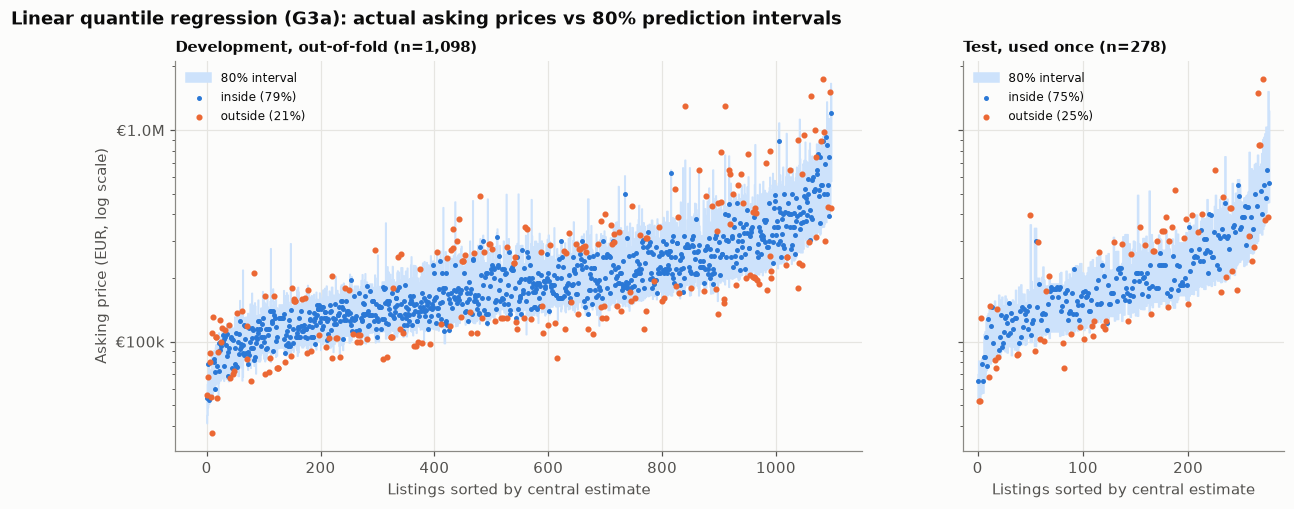

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True, gridspec_kw={'width_ratios': [3, 1.4]})
for ax, (lab, yy, d) in zip(axes, [('Development, out-of-fold (n=1,098)', y_dev, IOOF[('G3a', 0.80)]), ('Test, used once (n=278)', y_test, ITEST[('G3a', 0.80)])]):
    o = np.argsort(d['c']); x = np.arange(len(yy)); inside = ((yy >= d['lo']) & (yy <= d['hi']))[o]
    ax.fill_between(x, d['lo'][o], d['hi'][o], color='#cde2fb', step='mid', label='80% interval')
    ax.scatter(x[inside], yy[o][inside], s=5, color=vplot.BLUE, label=f'inside ({inside.mean():.0%})')
    ax.scatter(x[~inside], yy[o][~inside], s=9, color=vplot.ORANGE, label=f'outside ({(~inside).mean():.0%})')
    ax.set_yscale('log'); ax.yaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro)); ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    ax.set_title(lab, fontsize=10); ax.set_xlabel('Listings sorted by central estimate'); ax.legend(loc='upper left', fontsize=8)
axes[0].set_ylabel('Asking price (EUR, log scale)')
fig.suptitle('Linear quantile regression (G3a): actual asking prices vs 80% prediction intervals', x=0.01, ha='left', fontweight='bold')
vplot.save(fig, FIG, 'model_08_prediction_intervals'); plt.show()

**What it means** (pre-registered check, 278 test listings, used once):

| | G1 CV | G1 test | G3a CV | **G3a test** |
|---|---|---|---|---|
| Coverage, 80% level | 77.9% | 74.8% | 78.9% | **74.8%** |
| Median relative width, 80% | 58% | 59% | 64% | 64% |
| Interval score, 80% | €261k | €303k | €250k | €288k |
| Above upper / below lower, 80% | 11% / 11% | 14% / 11% | 11% / 10% | 13% / 13% |
| Coverage, 90% level | 87.9% | 85.6% | 89.0% | **86.0%** |
| Central estimate MAE | €50,527 | €57,478 | €50,855 | €56,176 |

- **On the test listings the ranges cover fewer flats than in cross-validation:** 74.8% instead of 78.9% (80% level), and 86.0% instead of 89.0% (90% level), at practically the same width.
- **This is within, but at the lower edge of, what the CV variation suggested.** The fold coverages ranged from 75% to 84%, and with 278 listings one binomial standard error is about 2.4 percentage points.
- **The test sample was also harder for the point estimate** (rule MAE €57.5k vs €50.5k in CV).
- **G3a stays better than G1 on the interval score** (€288k vs €303k).
- **Honest reading:** the 80% label should be understood as *"about 75–80% of comparable listings"*, not as a guarantee. No method, setting or threshold was changed after this check.
- **Quantile crossing:** the lower and upper bounds never crossed. The three quantiles are fitted **separately**, though, so in rare cases the median falls just outside its own range: 1 of 278 test listings at 80% (a flat in Berane, a city with no development listings), and 3 of 2,196 cross-validation cases. The range itself is unaffected.
- **Status:** a final retrospective check on data explored earlier for point predictions, **not** an independent external validation.

## 9. Error analysis

**What this code does:** Builds a table of the chosen model's test errors: actual price, prediction, error (positive = overestimate) and absolute error. Then it plots actual against predicted prices, and the distribution of the errors.

**Why we need it:** The average error hides where the model fails. These charts show whether errors are balanced or one-sided, and where the large ones are.

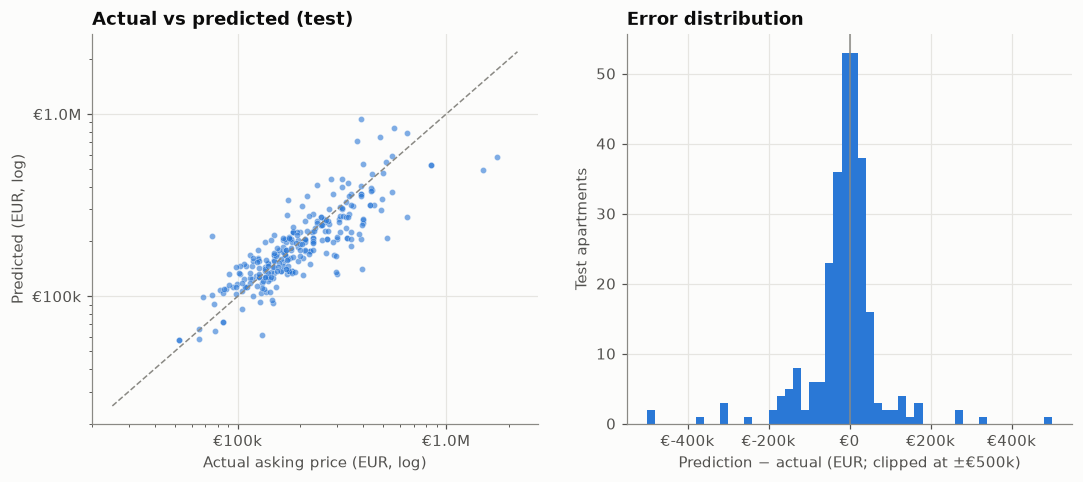

Overestimated: 125 | underestimated: 152 | median error €-4,909 | share within ±10%: 35%, within ±20%: 59%


In [26]:
err = test[['record_id', 'platform', 'city_clean', 'city_method', 'area_m2', 'rooms', 'price_eur']].copy()
err['predicted_eur'] = test_pred[CHOSEN]
err['error_eur'] = err['predicted_eur'] - err['price_eur']
err['abs_error_eur'] = err['error_eur'].abs()
err['abs_pct_error'] = 100 * err['abs_error_eur'] / err['price_eur']
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
ax = axes[0]
ax.scatter(err['price_eur'], err['predicted_eur'], s=16, alpha=0.6, color=vplot.BLUE, edgecolors='white', linewidths=0.3)
lim = [2.5e4, 2.2e6]
ax.plot(lim, lim, color=vplot.INK_3, ls='--', lw=1); ax.set_xscale('log'); ax.set_yscale('log')
for a in (ax.xaxis, ax.yaxis):
    a.set_major_formatter(mticker.FuncFormatter(vplot.euro)); a.set_minor_formatter(mticker.NullFormatter())
ax.set_xlabel('Actual asking price (EUR, log)'); ax.set_ylabel('Predicted (EUR, log)')
ax.set_title('Actual vs predicted (test)')
ax = axes[1]
ax.hist(err['error_eur'].clip(-500_000, 500_000), bins=50, color=vplot.BLUE)
ax.axvline(0, color=vplot.INK_3, lw=1)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro))
ax.set_xlabel('Prediction − actual (EUR; clipped at ±€500k)'); ax.set_ylabel('Test apartments')
ax.set_title('Error distribution')
vplot.save(fig, FIG, 'model_04_actual_vs_predicted'); plt.show()
print(f"Overestimated: {(err['error_eur'] > 0).sum()} | underestimated: {(err['error_eur'] < 0).sum()} | "
      f"median error €{err['error_eur'].median():,.0f} | share within ±10%: {(err['abs_pct_error'] <= 10).mean():.0%}, within ±20%: {(err['abs_pct_error'] <= 20).mean():.0%}")

**What this code does:** Summarises the errors by group: price band, size band, city (cities with ≥ 10 test listings), location method and platform. It always shows the number of listings (n).

**Why we need it:** Groups with few listings give unstable averages, so n has to be visible next to each number.

In [27]:
def by(col, data=err):
    g = data.groupby(col, observed=True)
    return pd.DataFrame({'n': g.size(), 'MAE': g['abs_error_eur'].mean(), 'median_abs_error': g['abs_error_eur'].median(),
                         'mean_error (bias)': g['error_eur'].mean(), 'median_abs_%': g['abs_pct_error'].median()}).round(0)
err['price_band'] = pd.cut(err['price_eur'], [0, 100_000, 200_000, 300_000, 500_000, np.inf], labels=['<100k', '100–200k', '200–300k', '300–500k', '≥500k'])
err['size_band'] = pd.cut(err['area_m2'], [0, 40, 60, 80, 120, np.inf], labels=['<40 m²', '40–60', '60–80', '80–120', '≥120 m²'])
err['location_known_by'] = err['city_method'].replace({'Original valid city': 'platform city', 'Explicit location match': 'explicit text',
                                                       'Reviewed settlement mapping': 'settlement mapping', 'Ambiguous': 'unknown', 'Conflict': 'unknown', 'Unknown': 'unknown'})
tables = {'price band': by('price_band'), 'size band': by('size_band'),
          'city (n ≥ 10)': by('city_clean').query('n >= 10').sort_values('n', ascending=False),
          'location method': by('location_known_by'), 'platform': by('platform')}
for k, t in tables.items():
    print(f'--- Errors by {k}'); display(t)
    t.to_csv(RES / f"errors_by_{k.split(' ')[0]}.csv")
err.to_csv(RES / 'error_analysis_test.csv', index=False)

--- Errors by price band


,n,MAE,median_abs_error,mean_error (bias),median_abs_%
price_band,,,,,
<100k,22,23843.0,17321.0,19681.0,18.0
100–200k,138,24558.0,20281.0,4385.0,14.0
200–300k,57,49276.0,33603.0,-16577.0,15.0
300–500k,50,101995.0,82918.0,-35640.0,25.0
≥500k,11,377891.0,310510.0,-289940.0,38.0


--- Errors by size band


,n,MAE,median_abs_error,mean_error (bias),median_abs_%
size_band,,,,,
<40 m²,34,21860.0,16877.0,-12066.0,16.0
40–60,115,32493.0,21577.0,-12069.0,15.0
60–80,70,55515.0,38006.0,-27160.0,17.0
80–120,38,67610.0,48147.0,-7026.0,14.0
≥120 m²,21,240173.0,134003.0,-43423.0,27.0


--- Errors by city (n ≥ 10)


,n,MAE,median_abs_error,mean_error (bias),median_abs_%
city_clean,,,,,
Podgorica,92,43312.0,30000.0,-14738.0,16.0
Budva,50,111145.0,42359.0,-41095.0,19.0
Herceg Novi,45,48904.0,29249.0,-17686.0,15.0
Kotor,17,58437.0,33445.0,2293.0,17.0
Kolašin,17,26579.0,22302.0,22.0,18.0
Bar,16,35543.0,11226.0,22980.0,8.0
Tivat,12,64608.0,13500.0,-32058.0,7.0


--- Errors by location method


,n,MAE,median_abs_error,mean_error (bias),median_abs_%
location_known_by,,,,,
explicit text,84,76352.0,30382.0,-18537.0,16.0
platform city,134,40006.0,24188.0,-15441.0,14.0
settlement mapping,54,66038.0,32833.0,-13931.0,16.0
unknown,6,106383.0,88150.0,-83283.0,38.0


--- Errors by platform


,n,MAE,median_abs_error,mean_error (bias),median_abs_%
platform,,,,,
Estitor,75,42282.0,32812.0,-12896.0,16.0
Realitica,197,63941.0,28000.0,-18780.0,16.0
Realitica Adriatic,6,35213.0,9631.0,-35213.0,5.0


**What this code does:** Draws the median absolute percentage error per price band and per size band, with n on each bar.

**Why we need it:** Percentage errors make cheap and expensive flats comparable.

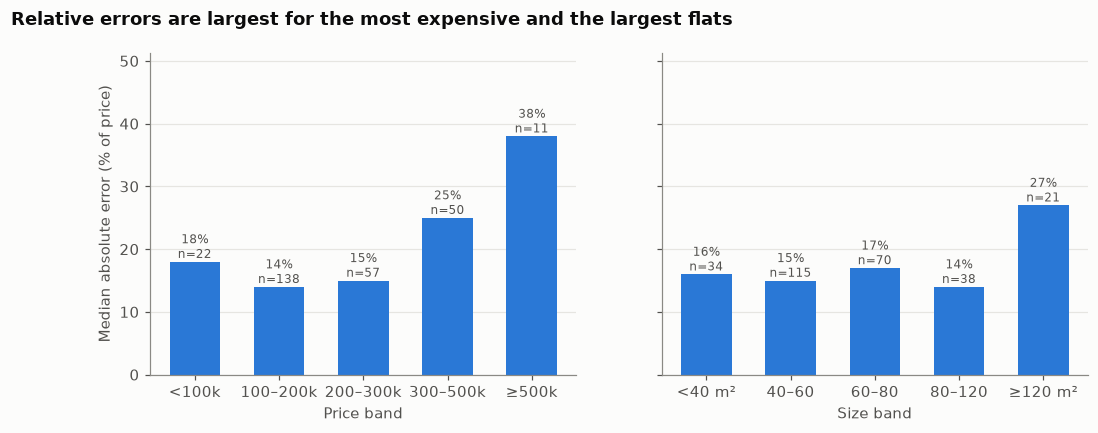

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (k, t) in zip(axes, [('price band', tables['price band']), ('size band', tables['size band'])]):
    ax.bar(t.index.astype(str), t['median_abs_%'], color=vplot.BLUE, width=0.6)
    for x, (v, n) in enumerate(zip(t['median_abs_%'], t['n'])):
        ax.text(x, v + 0.6, f'{v:.0f}%\nn={n}', ha='center', color=vplot.INK_2, fontsize=8)
    ax.set_xlabel(k.capitalize()); ax.grid(axis='x', visible=False)
axes[0].set_ylabel('Median absolute error (% of price)')
axes[0].set_ylim(0, max(tables['price band']['median_abs_%'].max(), tables['size band']['median_abs_%'].max()) * 1.35)
fig.suptitle('Relative errors are largest for the most expensive and the largest flats', x=0.01, ha='left', fontweight='bold')
vplot.save(fig, FIG, 'model_05_error_by_band'); plt.show()

**What this code does:** Lists the 10 largest test errors (platform, city, area, rooms and prices only; no IDs, links or text).

**Why we need it:** Looking at the worst cases shows what kind of flats the model cannot handle.

In [29]:
display(err.nlargest(10, 'abs_error_eur')[['platform', 'city_clean', 'location_known_by', 'area_m2', 'rooms', 'price_eur', 'predicted_eur', 'error_eur', 'abs_pct_error']].round(0))

,platform,city_clean,location_known_by,area_m2,rooms,price_eur,predicted_eur,error_eur,abs_pct_error
80,Realitica,Budva,explicit text,165.0,2.0,1750000.0,583513.0,-1166487.0,67.0
79,Realitica,Budva,explicit text,140.0,2.0,1500000.0,495102.0,-1004898.0,67.0
97,Realitica,Budva,settlement mapping,265.0,NaN,390000.0,937158.0,547158.0,140.0
194,Realitica,Tivat,platform city,68.0,1.0,650000.0,272000.0,-378000.0,58.0
165,Realitica,Bar,explicit text,241.0,NaN,375000.0,710990.0,335990.0,90.0
74,Estitor,Podgorica,platform city,188.0,3.0,846000.0,528750.0,-317250.0,38.0
271,Realitica,Podgorica,platform city,188.0,3.0,846000.0,528750.0,-317250.0,38.0
78,Realitica,Herceg Novi,settlement mapping,64.0,1.0,520000.0,209490.0,-310510.0,60.0
85,Realitica,Budva,explicit text,236.0,3.0,560000.0,834601.0,274601.0,49.0
95,Realitica,Kotor,explicit text,200.0,2.0,480000.0,749590.0,269590.0,56.0


### 9.1 Platform check: does a model trained on one platform work on the other?

**What this code does:** Trains the chosen pipeline on development rows from **Realitica only**, predicts the **Estitor** test rows (all in Podgorica), and compares with the full model on the same rows.

**Why we need it:** Estitor was collected differently (Podgorica only, at most 20 per neighbourhood). If performance collapses across platforms, the model would partly depend on how the data were collected.

In [30]:
real_dev = dev[dev['platform'] == 'Realitica']
est_test = test[test['platform'] == 'Estitor']
m_real = sklearn.base.clone(final_model) if CHOSEN not in BASELINES else build(CHOSEN)[0]
m_real.fit(real_dev[final_inputs], real_dev['price_eur'])
cross = pd.DataFrame([
    {'trained on': f'all development rows (n={len(dev)})', 'evaluated on': f'Estitor test rows (n={len(est_test)})',
     **vm.regression_metrics(est_test['price_eur'], final_model.predict(est_test[final_inputs]))},
    {'trained on': f'Realitica development rows only (n={len(real_dev)})', 'evaluated on': f'Estitor test rows (n={len(est_test)})',
     **vm.regression_metrics(est_test['price_eur'], m_real.predict(est_test[final_inputs]))},
])
display(cross.round({'MAE': 0, 'RMSE': 0, 'R2': 3, 'MedianAE': 0, 'MAPE_%': 1}))
cross.to_csv(RES / 'cross_platform_check.csv', index=False)

,trained on,evaluated on,MAE,RMSE,R2,MedianAE,MAPE_%
0,all development rows (n=1098),Estitor test rows (n=75),42282.0,62668.0,0.749,32812.0,18.5
1,Realitica development rows only (n=748),Estitor test rows (n=75),45376.0,67486.0,0.708,31818.0,19.3


**What it means** (chosen rule, 278 test listings; n shown for every group):

- **Balance.** 125 overestimated, 152 underestimated; median error −€4,909. 35% of estimates are within ±10% of the asking price, and 59% within ±20%.
- **Price bands.**
  - Flats ≥ €500k (n = 11) are **underestimated by about €290k on average** (median error 38%).
  - Flats under €100k (n = 22) are overestimated by about €20k.
  - The rule pulls prices towards the typical flat of the city. That is expected from a median-based rule, and it is the main weakness.
- **Size.** Flats ≥ 120 m² (n = 21) have a 27% median error; all other size bands have 14–17%.
- **Cities.**
  - Budva has the highest MAE (€111k, n = 50), but its median error is €42k. A few very expensive flats inflate its average.
  - Podgorica (n = 92) has an MAE of €43k.
  - Tivat and Bar have low median errors (7–8%) but few test listings (12–16).
- **Location method.**
  - Listings located by the platform field have the lowest MAE (€40k, n = 134, mostly Podgorica).
  - Explicit text (€76k, n = 84) and settlement mapping (€66k, n = 54) cover the more varied coast.
  - The 6 listings with unknown city have the largest errors (€106k).
- **Platforms.** Estitor €42k (n = 75), Realitica €64k (n = 197), Adriatic (n = 6, too few to judge).
  - **Cross-platform check:** a rule learned only from Realitica predicts the Estitor flats with an MAE of €45,376, against €42,282 when Estitor rows are also in training (+7%).
  - The model therefore transfers reasonably between platforms, but platform sampling affects the numbers somewhat.
- **Largest errors.**
  - Two Budva flats at €1.5–1.75M predicted around €0.5–0.6M.
  - A 265 m² Budva flat at €390k predicted at €937k.
  - A Podgorica flat listed on **both** platforms (one repeat group, both copies in the test set) appears twice. Repeat groups prevent leakage, but they mean some test flats count twice.

**What cannot be concluded:** the data contain no condition, view, floor, building quality or exact address. These are plausible reasons for the large errors, but **the data do not prove the cause of any single error**.

### 9.2 Where are the prediction intervals reliable?

**What this code does:** Computes the 80% coverage and median relative width of G1 and G3a per city (cities with ≥ 20 development listings), per region and per price band, from the cross-validation, next to the test result for the same groups. n is always shown.

**Why we need it:** A global 80% does not mean 80% in every city or price class. Users need to know where the ranges can be trusted.

In [31]:
COASTAL = {'Herceg Novi', 'Kotor', 'Tivat', 'Budva', 'Bar', 'Ulcinj'}
def group_cov(frame, yy, store, col, min_n):
    rows = []
    for g, idx in frame.groupby(col, observed=True).groups.items():
        idx = frame.index.get_indexer(idx)
        if len(idx) < min_n: continue
        for m in vi.METHODS:
            d = store[(m, 0.80)]
            rows.append({col: str(g), 'n': len(idx), 'method': m, 'coverage': np.mean((yy[idx] >= d['lo'][idx]) & (yy[idx] <= d['hi'][idx])),
                         'median_rel_width': np.median((d['hi'][idx] - d['lo'][idx]) / d['c'][idx]),
                         'above_upper_%': 100 * np.mean(yy[idx] > d['hi'][idx]), 'median_width_eur': np.median(d['hi'][idx] - d['lo'][idx])})
    return pd.DataFrame(rows)
bands = [0, 100_000, 200_000, 300_000, 500_000, np.inf]; blab = ['<100k', '100–200k', '200–300k', '300–500k', '≥500k']
region_of = lambda c: 'Unknown' if c == 'Unknown' else ('coastal' if c in COASTAL else 'continental')
devg = dev.assign(price_band=pd.cut(dev['price_eur'], bands, labels=blab), region=dev['city_clean'].map(region_of))
testg = test.assign(price_band=pd.cut(test['price_eur'], bands, labels=blab), region=test['city_clean'].map(region_of))
city_cv, city_te = group_cov(devg, y_dev, IOOF, 'city_clean', 20), group_cov(testg, y_test, ITEST, 'city_clean', 10)
band_cv, band_te = group_cov(devg, y_dev, IOOF, 'price_band', 1), group_cov(testg, y_test, ITEST, 'price_band', 1)
reg_cv, reg_te = group_cov(devg, y_dev, IOOF, 'region', 1), group_cov(testg, y_test, ITEST, 'region', 1)
for name, a, b, key in [('city', city_cv, city_te, 'city_clean'), ('price band', band_cv, band_te, 'price_band'), ('region', reg_cv, reg_te, 'region')]:
    t = a.merge(b, on=[key, 'method'], how='left', suffixes=('_cv', '_test'))
    t.to_csv(RES / f"interval_by_{name.replace(' ', '_')}.csv", index=False)
    print(f'--- 80% intervals by {name} (CV on development; test where the group has enough test listings)')
    display(t[[key, 'method', 'n_cv', 'coverage_cv', 'median_rel_width_cv', 'above_upper_%_cv', 'n_test', 'coverage_test', 'above_upper_%_test']].round(2))

--- 80% intervals by city (CV on development; test where the group has enough test listings)


,city_clean,method,n_cv,coverage_cv,median_rel_width_cv,above_upper_%_cv,n_test,coverage_test,above_upper_%_test
0,Bar,G1,62,0.76,0.60,12.90,16.0,0.88,0.00
1,Bar,G3a,62,0.79,0.58,12.90,16.0,0.88,0.00
2,Budva,G1,184,0.80,0.87,9.78,50.0,0.72,16.00
3,Budva,G3a,184,0.81,0.83,10.33,50.0,0.68,18.00
4,Cetinje,G1,27,0.74,0.40,11.11,NaN,NaN,NaN
5,Cetinje,G3a,27,0.81,0.45,11.11,NaN,NaN,NaN
6,Herceg Novi,G1,180,0.79,0.83,11.11,45.0,0.84,8.89
7,Herceg Novi,G3a,180,0.78,0.83,11.67,45.0,0.80,8.89
8,Kolašin,G1,41,0.80,0.53,12.20,17.0,0.65,11.76
9,Kolašin,G3a,41,0.78,0.54,9.76,17.0,0.65,11.76


--- 80% intervals by price band (CV on development; test where the group has enough test listings)


,price_band,method,n_cv,coverage_cv,median_rel_width_cv,above_upper_%_cv,n_test,coverage_test,above_upper_%_test
0,<100k,G1,92,0.65,0.52,5.43,22,0.64,0.00
1,<100k,G3a,92,0.60,0.48,6.52,22,0.50,0.00
2,100–200k,G1,561,0.84,0.53,4.63,138,0.84,5.80
3,100–200k,G3a,561,0.84,0.57,4.28,138,0.85,2.90
4,200–300k,G1,270,0.78,0.75,15.19,57,0.74,19.30
5,200–300k,G3a,270,0.82,0.74,13.70,57,0.74,19.30
6,300–500k,G1,129,0.74,0.84,20.16,50,0.64,28.00
7,300–500k,G3a,129,0.76,0.88,21.71,50,0.66,28.00
8,≥500k,G1,46,0.46,0.83,52.17,11,0.36,54.55
9,≥500k,G3a,46,0.50,0.96,50.00,11,0.45,54.55


--- 80% intervals by region (CV on development; test where the group has enough test listings)


,region,method,n_cv,coverage_cv,median_rel_width_cv,above_upper_%_cv,n_test,coverage_test,above_upper_%_test
0,Unknown,G1,27,0.52,0.77,25.93,6,0.50,33.33
1,Unknown,G3a,27,0.74,2.01,11.11,6,0.67,16.67
2,coastal,G1,579,0.78,0.84,11.05,148,0.78,10.81
3,coastal,G3a,579,0.79,0.80,11.05,148,0.76,10.81
4,continental,G1,492,0.79,0.51,10.37,124,0.72,16.94
5,continental,G3a,492,0.79,0.52,10.37,124,0.73,14.52


**What this code does:** Draws G3a's cross-validated 80% coverage and median relative width per city, with the test coverage as a marker where a city has at least 10 test listings.

**Why we need it:** One picture of where the ranges are reliable and how informative they are.

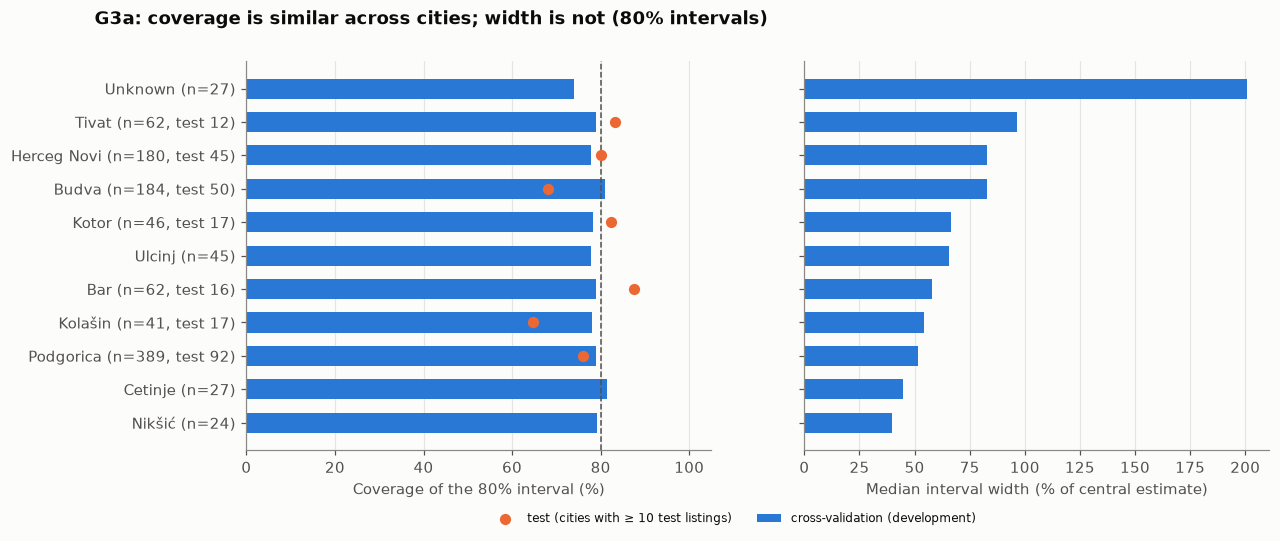

In [32]:
c3 = city_cv[city_cv['method'] == 'G3a'].sort_values('median_rel_width'); t3 = city_te[city_te['method'] == 'G3a'].set_index('city_clean')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True); yy = np.arange(len(c3))
axes[0].barh(yy, 100 * c3['coverage'], color=vplot.BLUE, height=0.6, label='cross-validation (development)')
tc = c3['city_clean'].map(t3['coverage']); tn = c3['city_clean'].map(t3['n'])
axes[0].scatter(100 * tc, yy, color=vplot.ORANGE, zorder=3, s=40, label='test (cities with ≥ 10 test listings)')
axes[0].axvline(80, color=vplot.INK_2, ls='--', lw=1); axes[0].set_xlim(0, 105); axes[0].set_xlabel('Coverage of the 80% interval (%)')
axes[0].set_yticks(yy, [f"{c} (n={n}" + (f", test {int(t)})" if pd.notna(t) else ")") for c, n, t in zip(c3['city_clean'], c3['n'], tn)])
axes[1].barh(yy, 100 * c3['median_rel_width'], color=vplot.BLUE, height=0.6); axes[1].set_xlabel('Median interval width (% of central estimate)')
axes[0].legend(loc='upper center', bbox_to_anchor=(1.05, -0.13), ncols=2, fontsize=8)
for a in axes: a.grid(axis='y', visible=False)
fig.suptitle('G3a: coverage is similar across cities; width is not (80% intervals)', x=0.01, ha='left', fontweight='bold')
vplot.save(fig, FIG, 'model_09_interval_by_city'); plt.show()

**What this code does:** Draws the 80% coverage of G1 and G3a per actual price band, for cross-validation and test, with n.

**Why we need it:** The previous analysis showed that expensive flats are underestimated. This checks whether the ranges at least contain them.

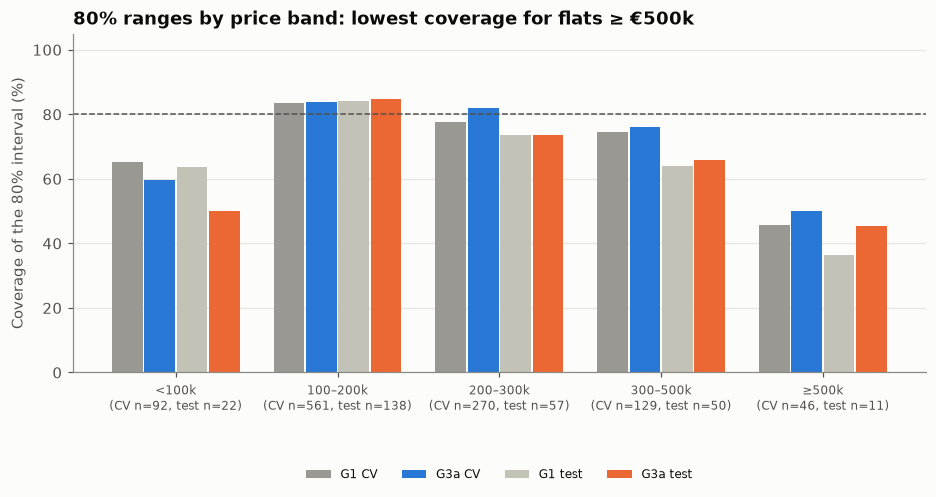

In [33]:
fig, ax = plt.subplots(figsize=(10, 4)); x = np.arange(len(blab)); w = 0.2
for j, (m, src, lab, col) in enumerate([('G1', band_cv, 'G1 CV', vplot.GRAY), ('G3a', band_cv, 'G3a CV', vplot.BLUE), ('G1', band_te, 'G1 test', '#c3c2b7'), ('G3a', band_te, 'G3a test', vplot.ORANGE)]):
    d = src[src['method'] == m].set_index('price_band').reindex(blab)
    ax.bar(x + (j - 1.5) * w, 100 * d['coverage'], width=w * 0.95, color=col, label=lab)
ncv = band_cv[band_cv.method == 'G3a'].set_index('price_band').reindex(blab)['n']; nte = band_te[band_te.method == 'G3a'].set_index('price_band').reindex(blab)['n']
ax.set_xticks(x, [f'{b}\n(CV n={a}, test n={t})' for b, a, t in zip(blab, ncv, nte)], fontsize=8)
ax.axhline(80, color=vplot.INK_2, ls='--', lw=1); ax.set_ylim(0, 105); ax.set_ylabel('Coverage of the 80% interval (%)')
ax.set_title('80% ranges by price band: lowest coverage for flats ≥ €500k'); ax.legend(ncols=4, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.25))
ax.grid(axis='x', visible=False)
vplot.save(fig, FIG, 'model_10_interval_by_price_band'); plt.show()

**What it means** (G3a, 80% intervals; CV on development / test; n shown):

| Group | CV n | CV coverage | Median width | Test n | Test coverage |
|---|---|---|---|---|---|
| Podgorica | 389 | 0.79 | 52% | 92 | 0.76 |
| Budva | 184 | 0.81 | 83% | 50 | 0.68 |
| Herceg Novi | 180 | 0.78 | 83% | 45 | 0.80 |
| Tivat | 62 | 0.79 | 97% | 12 | 0.83 |
| Bar | 62 | 0.79 | 58% | 16 | 0.88 |
| Kotor | 46 | 0.78 | 66% | 17 | 0.82 |
| Kolašin | 41 | 0.78 | 54% | 17 | 0.65 |
| Ulcinj / Cetinje / Nikšić | 45 / 27 / 24 | 0.78 / 0.81 / 0.79 | 66% / 45% / 40% | < 10 each | – |
| Coastal / continental | 579 / 492 | 0.79 / 0.79 | 80% / 52% | 148 / 124 | 0.76 / 0.73 |

- **Coverage is similar across cities in cross-validation (0.78–0.81), but the width is not.** The ranges are about half as wide in continental cities as on the coast, so they are **more informative inland**.
- **The test values per city rest on 12–92 listings,** so they vary more (0.65–0.88). They should not be read as city-specific reliability.
- **Expensive flats:**
  - Flats ≥ €500k are covered in only **50%** of CV cases (n = 46) and **45%** of test cases (n = 11). About half lie **above** the upper bound, even though their ranges are very wide (median ≈ 96% of the estimate).
  - Flats €300–500k: 76% (CV) and 66% (test).
- **Cheap flats** (< €100k) are covered 60% (CV) and 50% (test, n = 22) of the time. Their misses are below the lower bound: the methods pull them towards the typical flat.
- **What this means in practice:** the ranges describe typical flats reasonably well. They should **not** be trusted for luxury or unusually cheap flats.

## 10. Interpretation

**What this code does:** Computes **permutation importance** for the chosen model on the test rows: each input column (area, rooms, city) is shuffled in turn, 20 times, and the increase in MAE is recorded.

**Why we need it:** It shows which inputs the model relies on. Shuffling a column that matters makes the predictions much worse. It shows reliance, **not** cause and effect.

,input,MAE increase (EUR),std
1,city_clean,12343.0,1526.0
0,area_m2,67664.0,3606.0


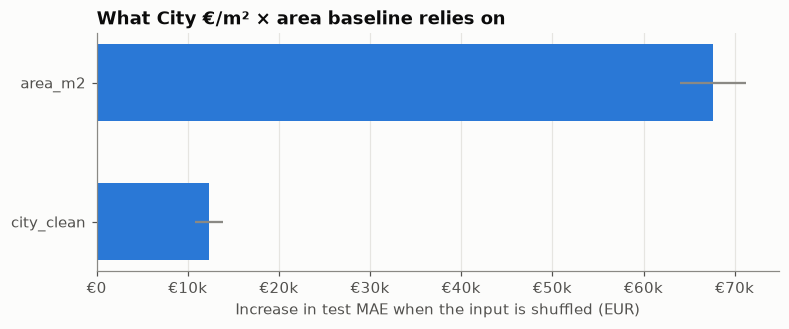

In [34]:
pi = permutation_importance(final_model, test[final_inputs], y_test, scoring='neg_mean_absolute_error', n_repeats=20, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({'input': final_inputs, 'MAE increase (EUR)': pi.importances_mean, 'std': pi.importances_std}).sort_values('MAE increase (EUR)')
display(imp.round(0)); imp.to_csv(RES / 'permutation_importance.csv', index=False)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(imp['input'], imp['MAE increase (EUR)'], xerr=imp['std'], color=vplot.BLUE, height=0.55, error_kw=dict(ecolor=vplot.INK_3))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro))
ax.set_xlabel('Increase in test MAE when the input is shuffled (EUR)')
ax.set_title(f'What {CHOSEN} relies on'); ax.grid(axis='y', visible=False)
vplot.save(fig, FIG, 'model_06_permutation_importance'); plt.show()

**What this code does:** Shows how the chosen model builds a prediction. For a linear model these are its coefficients; for the city €/m² rule this is the learned price per m² of each city and the fallback value.

**Why we need it:** For a linear model the coefficients are the clearest explanation of how a prediction is built.

In [35]:
est = final_model.regressor_ if hasattr(final_model, 'regressor_') else final_model
inner = est.named_steps['model'] if hasattr(est, 'named_steps') else est
if hasattr(inner, 'coef_'):
    names = est.named_steps['preprocess'].get_feature_names_out()
    coef = pd.DataFrame({'feature': names, 'coefficient': inner.coef_})
    if hasattr(final_model, 'regressor_'):
        coef['effect_on_price_%'] = 100 * (np.exp(coef['coefficient']) - 1)
    city = coef[coef['feature'].str.startswith('city_clean_')].copy()
    city['city'] = city['feature'].str.replace('city_clean_', '', regex=False)
    display(coef[~coef['feature'].str.startswith('city_clean_')].round(3))
    display(city.sort_values('coefficient', ascending=False)[['city', 'coefficient'] + (['effect_on_price_%'] if 'effect_on_price_%' in city else [])].round(3))
    coef.to_csv(RES / 'final_model_coefficients.csv', index=False)
elif hasattr(inner, 'city_ppm_'):
    rule = pd.Series(inner.city_ppm_, name='median €/m² learned from training rows').sort_values(ascending=False).round(0).to_frame()
    rule['training listings'] = rule.index.map(dev['city_clean'].value_counts())
    display(rule)
    print(f"Fallback for Unknown and cities with < {inner.min_count} training listings: €{inner.fallback_ppm_:,.0f}/m²")
    rule.to_csv(RES / 'final_model_city_price_per_m2.csv')
else:
    print(f'{CHOSEN} has no coefficients; see permutation importance above.')

,median €/m² learned from training rows,training listings
Tivat,4000.0,62
Kotor,3748.0,46
Budva,3536.0,184
Herceg Novi,3273.0,180
Bar,2950.0,62
Podgorica,2812.0,389
Žabljak,2725.0,10
Kolašin,2561.0,41
Ulcinj,2315.0,45
Nikšić,1879.0,24


Fallback for Unknown and cities with < 10 training listings: €3,000/m²


**What it means:** the chosen method is easy to explain. Its prediction is **area × the median asking price per m² of the city in the training data**:

| City | Learned €/m² | Training listings |
|---|---|---|
| Tivat | 4,000 | 62 |
| Kotor | 3,748 | 46 |
| Budva | 3,536 | 184 |
| Herceg Novi | 3,273 | 180 |
| Bar | 2,950 | 62 |
| Podgorica | 2,812 | 389 |
| Žabljak | 2,725 | 10 |
| Kolašin | 2,561 | 41 |
| Ulcinj | 2,315 | 45 |
| Nikšić | 1,879 | 24 |
| Cetinje | 1,829 | 27 |
| **Fallback** (Unknown, or < 10 listings) | **3,000** | – |

**Permutation importance:**
- Shuffling the **area** makes the test MAE worse by about **€67,700**.
- Shuffling the **city** makes it worse by about **€12,300**.
- Rooms are not used by this rule.

So size drives most of the prediction, and the city adjusts the price level. This describes how the rule works. It does **not** prove that size or city *cause* prices.

**How reliable is it?** Half of the test estimates are within €28,500 of the asking price, but the average error is €57,500 because of a few large misses on expensive flats. Žabljak's median rests on only 10 listings and Nikšić's on 24, so they are much less certain than Podgorica's.

### 10.1 Example predictions for comparable flats in four cities

**What this code does:** For a hypothetical 70 m² flat in Podgorica, Nikšić, Budva and Tivat, it shows: the final **point estimate** (city €/m² rule), and G3a's **80% and 90% ranges** with its own central (median) estimate, all fitted on the 1,098 development listings. It also shows the number of similar development listings (same city, area within ±15%), the room count used as input (median rooms of those similar listings), and G3a's cross-validated coverage in that city.

**Why we need it:** Comparable flats show how location changes both the price level and the uncertainty. These are **illustrations of one flat's asking-price range** from trained methods. They are not valuations, and not evaluations on real listings.

In [36]:
EX = pd.DataFrame({'city_clean': ['Podgorica', 'Nikšić', 'Budva', 'Tivat'], 'area_m2': [70.0] * 4})
sim = [dev[(dev['city_clean'] == r.city_clean) & dev['area_m2'].between(0.85 * r.area_m2, 1.15 * r.area_m2)] for r in EX.itertuples()]
EX['similar_dev_listings'] = [len(w) for w in sim]
EX['rooms'] = [float(w['rooms'].median()) for w in sim]
EX['point_estimate_rule'] = final_model.predict(EX[final_inputs]).round(-3)
for lv, alpha in LEVELS.items():
    lo, hi, c = vi.QuantileRegressionInterval(alpha).fit(dev).predict(EX)
    EX[f'G3a_low_{int(round(lv*100))}'], EX[f'G3a_high_{int(round(lv*100))}'] = lo.round(-3), hi.round(-3)
EX['G3a_median'] = c.round(-3)
EX['G3a_cv_coverage_80_in_city'] = EX['city_clean'].map(city_cv[city_cv.method == 'G3a'].set_index('city_clean')['coverage']).round(2)
EX['limitation'] = np.where(EX['similar_dev_listings'] < 10, 'few similar listings: rough indication only', '')
display(EX); EX.to_csv(RES / 'illustrative_predictions.csv', index=False)

,city_clean,area_m2,similar_dev_listings,rooms,point_estimate_rule,G3a_low_80,G3a_high_80,G3a_low_90,G3a_high_90,G3a_median,G3a_cv_coverage_80_in_city,limitation
0,Podgorica,70.0,133,2.0,197000.0,149000.0,257000.0,140000.0,272000.0,194000.0,0.79,
1,Nikšić,70.0,12,2.0,132000.0,102000.0,163000.0,98000.0,180000.0,132000.0,0.79,
2,Budva,70.0,33,2.0,248000.0,174000.0,373000.0,154000.0,429000.0,247000.0,0.81,
3,Tivat,70.0,23,2.0,280000.0,225000.0,479000.0,212000.0,539000.0,276000.0,0.79,


**What this code does:** Draws the four examples: the 80% range (thick bar), the 90% range (thin line), G3a's median (dot) and the point estimate of the final rule (diamond).

**Why we need it:** A presentation-ready comparison of the same flat across four cities.

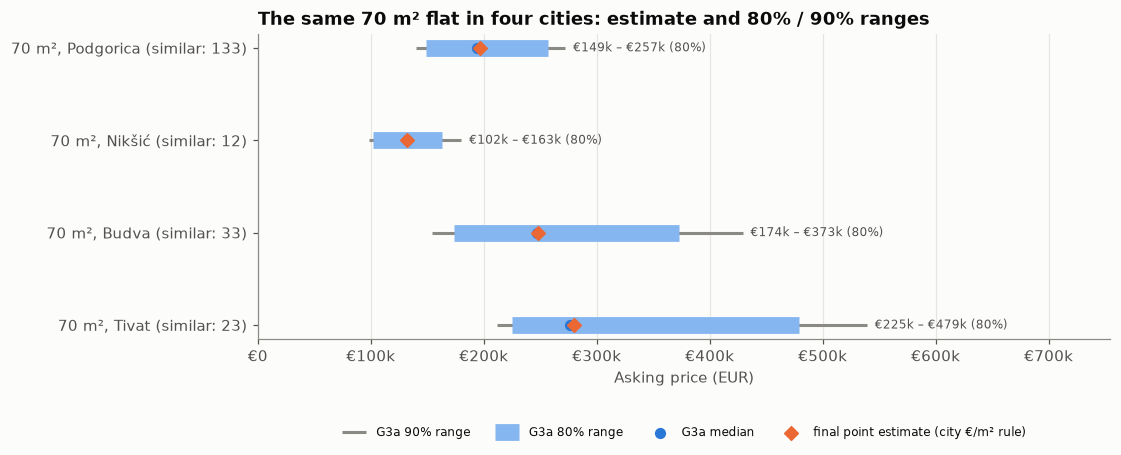

In [37]:
fig, ax = plt.subplots(figsize=(10, 3.6)); yy = np.arange(len(EX))[::-1]
ax.hlines(yy, EX['G3a_low_90'], EX['G3a_high_90'], color=vplot.INK_3, lw=2, label='G3a 90% range')
ax.hlines(yy, EX['G3a_low_80'], EX['G3a_high_80'], color='#86b6ef', lw=11, label='G3a 80% range')
ax.scatter(EX['G3a_median'], yy, color=vplot.BLUE, s=40, zorder=3, label='G3a median')
ax.scatter(EX['point_estimate_rule'], yy, color=vplot.ORANGE, marker='D', s=40, zorder=4, label='final point estimate (city €/m² rule)')
for yi, r in zip(yy, EX.itertuples()):
    ax.text(r.G3a_high_90, yi, f"  €{r.G3a_low_80/1000:.0f}k – €{r.G3a_high_80/1000:.0f}k (80%)", va='center', fontsize=8, color=vplot.INK_2)
ax.set_yticks(yy, [f'70 m², {r.city_clean} (similar: {r.similar_dev_listings})' for r in EX.itertuples()])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro)); ax.set_xlabel('Asking price (EUR)'); ax.set_xlim(0, EX['G3a_high_90'].max() * 1.4)
ax.set_title('The same 70 m² flat in four cities: estimate and 80% / 90% ranges'); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncols=4, fontsize=8); ax.grid(axis='y', visible=False)
vplot.save(fig, FIG, 'model_11_example_ranges'); plt.show()

**What it means** (all methods fitted on the 1,098 development listings; hypothetical 70 m², 2-room flats):

| City | Similar dev listings | Final point estimate (rule) | G3a median | G3a 80% range | G3a 90% range | G3a CV coverage in city |
|---|---|---|---|---|---|---|
| Podgorica | 133 | €197k | €194k | €149k – €257k | €140k – €272k | 0.79 |
| Nikšić | 12 | €132k | €132k | €102k – €163k | €98k – €180k | 0.79 |
| Budva | 33 | €248k | €247k | €174k – €373k | €154k – €429k | 0.81 |
| Tivat | 23 | €280k | €276k | €225k – €479k | €212k – €539k | 0.79 |

- **Two different methods are shown.** The **final point estimate** comes from the city €/m² rule. The **range** and its median come from the quantile regression G3a. Their central values are close (within €4k) but not identical.
- **The ranges are asymmetric:** for Tivat, the 80% range reaches about €50k below the median but about €200k above it, because high asking prices are more spread out.
- **The width depends strongly on location:** €61k in Nikšić, €108k in Podgorica, €199k in Budva and €254k in Tivat for the same flat size.
- **Limitations:**
  - Nikšić has only 12 similar development listings, so its range is less certain than Podgorica's.
  - The rooms input is the median of the similar listings (2 in every city).
  - These are illustrations of one flat's **asking-price** range, not valuations. Condition, view and floor are unknown to the model.

### 10.2 How to read a prediction interval

| Concept | Meaning in this project |
|---|---|
| **Point prediction** | One number: the best single estimate of a flat's asking price (here the city €/m² rule) |
| **Prediction interval** | A range for the asking price of **one** flat, e.g. €149k–€257k at 80%. It describes the uncertainty about an individual flat |
| **Confidence interval** (not used here) | A range for an **average** or a model parameter, e.g. "the mean asking price in Podgorica". It is much narrower than a prediction interval, because averages vary less than individual flats. **The ranges in this project are not confidence intervals** |
| **Quantile** | The q-quantile is the value below which a share q of prices fall. The 10% and 90% quantiles enclose the middle 80%. Quantile regression predicts these values directly |
| **Empirical coverage** | The share of real flats whose actual asking price fell inside their range: 78.9% in cross-validation and 74.8% on the test set for the 80% ranges |
| **Width** | Upper minus lower bound. A **wider** range covers more flats but is less useful. A range from €0 to €10M would always "work" and tell nothing. Coverage must always be judged **together** with width; the interval score combines both |
| **Pinball loss** | The error measure for a quantile. It penalises an estimate that is too high by (1 − q) and one that is too low by q, so a 90% quantile is punished more for being too low |

**What the coverage does *not* mean:**
- An 80% coverage overall does **not** guarantee 80% for every city, price class or individual flat. Expensive flats, for example, were covered only about half of the time.
- There is **no formal guarantee** at all:
  - quantile regression gives none;
  - the data are a convenience sample of adverts from three platforms, with dependent repeated listings and no time order, so the assumptions behind formal conformal guarantees (exchangeable data) are doubtful.
- All coverages are **empirical estimates** for listings like those in this sample.

## 11. Limitations & ethics

**Limitations**

1. **Asking prices, not sale prices.** Adverts can be above or below the final price, and some may be outdated or wrong.
2. **Convenience sample.** The data are online adverts from three sources:
   - Estitor covers **only Podgorica**, with at most 20 adverts per neighbourhood;
   - Realitica Adriatic has only 30 listings;
   - small towns have few or no listings.

   The results describe *this sample*, not the Montenegrin market.
3. **Few inputs.** There is no condition, floor, view, building age, exact location or parking. Bathrooms exist only on one platform. Simulated attributes must not be used.
4. **No dates.** It is impossible to tell whether prices are current, to study trends, or to test on later adverts.
5. **The test set is not untouched.** I had already explored this dataset and seen test results in my earlier notebooks. During development, a smoke test also ran cross-validation on all primary rows, including the later test rows (documented in `docs/validation_report.md`). The point-prediction test result and the later interval check are therefore **retrospective internal checks, not independent validation**.
6. **Prediction intervals:**
   - coverage is lower on the test set (74.8%) than in cross-validation (78.9%);
   - there is no formal coverage guarantee;
   - coverage is poor for flats ≥ €500k (about 50%) and for cheap flats (about 60%);
   - the city-level estimates for small cities rest on few listings.
7. **Repeat detection** is exact-match only. Re-posts with small changes can remain.
8. **Settlement mapping** relies on a list of 15 settlement names verified against the Monstat register. Ambiguous names stay unknown.
9. **Exploratory follow-up questions.** The €/m²-rule comparison and the uncertainty question were formulated after the first results.

**Ethics and risks**

- **Not a valuation.** Neither the estimate nor the range is a certified market value. They must not be used alone for lending, tax or legal decisions.
- **False precision.** A range can still be misread as a guarantee. It must always be shown together with its measured coverage and its limits (e.g. luxury flats).
- **Anchoring.** A valuer who sees an estimate first may lean towards it. Estimates like these can only complement professional judgement, not replace it.
- **Uneven quality.** Errors and ranges are larger for expensive flats, the coast and unknown locations, so the estimates are less informative for some areas and segments than for others.
- **Data rights and privacy.** Platform terms and redistribution rights are not documented, and the raw file contains sensitive appraisal file paths. The exported data contain no URLs, IDs or free text (see `docs/privacy_and_data_rights.md`).

## 12. Conclusion & next steps

**Answer to the research question**

- **How accurately can asking prices be estimated?** With area, rooms and city, the typical error is about 16% (median absolute percentage error 15.6%). The mean absolute error is €57,500 on the test set (€50,500 in cross-validation).
  - A transparent **city €/m² × area** rule does this **as well as machine learning** on average. No ML model, including hybrids that learn corrections to the rule, improved on it reliably.
- **How reliably can the uncertainty be quantified?** Linear quantile regression gives 80% ranges that contain about 79% of asking prices in cross-validation and 75% on the test listings.
  - The median total width is 64% of the estimate: about half as wide in continental cities as on the coast.
  - The ranges are reliable for typical flats. They miss about half of the flats above €500k.

**What worked**
- **Cleaning the data properly mattered more than the choice of algorithm.** The cleaning excluded 4,927 non-market rows (including 2,000 mislabelled simulated rows), 36 rentals and 47 re-posts, and cut unknown cities from 49% to 2.4%.
- **Location information is clearly valuable:** Random Forest test MAE fell from €62.4k to €56.5k when the original city field was replaced by the cleaned city.
- **Quantile regression** turns an uncertain point estimate into an honest range, and shows where the estimate can be trusted.
- **An honest protocol** (group-aware splits, nested tuning, selection rules and a test check fixed in advance) gives results that can be checked, even when they are not flattering.

**What did not work**
- More complex models, hybrids, €/m² targets, room-count estimation and extra features did not improve the point estimate.
- Expensive, very large and very cheap flats remain poorly estimated, and poorly covered by the ranges.
- An earlier impression that tree models control large errors better did not hold in cross-validation.

**Main message:** *the goal is not just to predict a price, but to understand how much we can trust that prediction.*

**Next steps**
1. Collect adverts **with dates**, regularly. This enables trend analysis and a truly independent test on new listings.
2. Add **neighbourhood, condition, floor, view and building age** where available and reliable. These are the most likely sources of the remaining error and of the wide coastal ranges.
3. Collect more listings in under-represented municipalities, and balance the platforms.
4. Study the **professional appraisals separately** (valuation vs asking price).
5. Evaluate any future method on **newly collected adverts** before drawing practical conclusions, and always report the estimate together with its range and measured coverage.